# What GD learns when nothing is pinned — the *relaxed* run

`obesrving_the_weights.ipynb` looked at the **qk-only** setup: $W_{ov}$, the log readout and the
unembedding were all frozen to the hand construction, and only the QK circuit was free. This
notebook repeats every one of those plots for the run where those constraints are **lifted**.

**Run shown:** `runs/equi_opt-adam_lr-0.003_b-256_init-normal_ep-2000` — the latest relaxed run in
this folder. Trained by `train_with_equiprobable.py` on the equiprobable-successor dataset,
7 thresholds $\times$ 2 architectures, 2000 epochs, adam / lr 0.003 / batch 256 / `init=normal`.

### What is free here and what is not

| circuit | qk-only run | **this relaxed run** |
|---|---|---|
| $W_{qk}$ layer 1 & 2 | trained | **trained** |
| $W_{ov}$ layer 1 & 2 | pinned to $I_8$ block | **trained** |
| unembedding `fc_out` (8x324 + bias) | pinned identity selector, no bias | **trained** |
| the log | `log()` applied directly, no residual | fixed GELU basis in `ff1/ff2`, **residual** |

The log is the one thing still installed rather than learned — in every folder-14 run the readout
FFN is the fitted log core (`freeze_readout`). What changed is that GD now has to discover the
**value circuit and the unembedding** on its own, so two extra gauge freedoms appear:

$$W_{ov}\to W_{ov}M,\qquad \texttt{fc\_out}\to \texttt{fc\_out}\,M^{-1}$$

for any invertible $M$ acting on the 108 attention-output coordinates. Individual $W_{ov}$ and
`fc_out` panels are therefore **not** comparable to the construction cell-by-cell; only their
composition is, and section 9 plots exactly that composition.

### Reading conventions (same as the construction notebook)

* Everything is shown as $W^\top$, shape $[\text{in}\times\text{out}]$ — rows = input dims,
  columns = output dims.
* Symmetric-log colour map, linear inside $|w|<1$, red positive / blue negative.
* **Each panel carries its own scale.** The learned matrices are orders of magnitude smaller than
  the construction; a shared scale renders them blank.
* Black lines mark residual-stream block boundaries.

```
layer 1 input  (108) :  0:8 token one-hot | 8:108 position one-hot
layer 2 input  (216) :  0:8 token | 8:108 position | 108:116 L1-out token | 116:216 L1-out pos
full stream    (324) :  ... plus 216:224 L2-out token slots | 224:324 L2-out rest
attention out  (108) :  0:8 token slots | 8:108 unused (in the construction)
```


In [1]:
import os, glob, json, importlib.util
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm

V, VS, T = 8, 4, 100
D, IN2 = V + T, 2 * (V + T)          # 108, 216
DFULL   = IN2 + D                     # 324 -- the full residual stream
SD = D ** 0.5
ALPHA_REC, GAMMA, P1, P2, NF, BIG = 20.0, -50000.0, 1000.0, 50.0, 10.0, -1e9

# ---- the hand construction (identical to obesrving_the_weights.ipynb) -------------------
Wq1 = torch.eye(D) * SD
T1 = torch.zeros(D, D)
for k in range(VS, V):
    T1[k, :] = BIG
for tq in range(T):
    for tk in range(T):
        T1[V + tk, V + tq] = BIG if tq == tk else -ALPHA_REC * (tq - tk)
Wk1 = T1.t()
Wv1 = torch.zeros(D, D); Wv1[:V, :V] = torch.eye(V)
Wo1 = torch.eye(D)

Wq2 = torch.zeros(D, IN2)
Wq2[:VS, :VS] = torch.eye(VS) * SD * P1
Wq2[:VS, D:D + VS] = torch.eye(VS) * SD * P2
for v in range(V):
    Wq2[VS, v] = SD * NF
Wk2 = torch.zeros(D, IN2); Wk2[:V, D:D + V] = torch.eye(V)
for v in range(VS, V):
    Wk2[VS, v] = GAMMA
Wv2 = torch.zeros(D, IN2); Wv2[:V, :V] = torch.eye(V)
Wo2 = torch.eye(D)

RAW  = {'(Wq1)^T': Wq1.t(), '(Wk1)^T': Wk1.t(), '(Wv1)^T': Wv1.t(), '(Wo1)^T': Wo1.t(),
        '(Wq2)^T': Wq2.t(), '(Wk2)^T': Wk2.t(), '(Wv2)^T': Wv2.t(), '(Wo2)^T': Wo2.t()}
PROD = {'W_qk layer1': Wq1.t() @ Wk1, 'W_ov layer1': Wv1.t() @ Wo1.t(),
        'W_qk layer2': Wq2.t() @ Wk2, 'W_ov layer2': Wv2.t() @ Wo2.t()}

# the construction's unembedding: identity selector on the layer-2 count slots, no bias
FC_C = torch.zeros(V, DFULL)
for v in range(V):
    FC_C[v, IN2 + v] = 1.0
FCB_C = torch.zeros(V)

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'font.size': 11,
                     'axes.titlesize': 12, 'axes.grid': False})
ART = 'artifacts/relaxed_weights'
os.makedirs(ART, exist_ok=True)
print('construction rebuilt;  artifacts ->', ART)


construction rebuilt;  artifacts -> artifacts/relaxed_weights


In [2]:
def bounds(n):
    if n == D:      return [V]
    if n == IN2:    return [V, D, D + V]
    if n == DFULL:  return [V, D, D + V, IN2, IN2 + V]
    return [V] if n >= V else []

def show(ax, M, title, lw=0.9, aspect='equal'):
    A = M.detach().numpy() if torch.is_tensor(M) else np.asarray(M)
    a = np.abs(A[A != 0])
    vmax = float(a.max()) if a.size else 1.0
    norm = SymLogNorm(linthresh=min(1.0, vmax / 100.0), linscale=0.6,
                      vmin=-vmax, vmax=vmax, base=10)
    im = ax.imshow(A, cmap='RdBu_r', norm=norm, interpolation='nearest', aspect=aspect)
    for b in bounds(A.shape[0]):
        ax.axhline(b - .5, color='k', lw=lw)
    for b in bounds(A.shape[1]):
        ax.axvline(b - .5, color='k', lw=lw)
    ax.set_title(f'{title}   {A.shape[0]}x{A.shape[1]}   '
                 f'|max| {np.abs(A).max():.3g}', fontsize=11)
    ax.set_xlabel('output / key dim'); ax.set_ylabel('input / query dim')
    return im

def annot(ax, M, r0, r1, c0, c1, title, rlab=None, clab=None, fmt='{:.4g}', fs=8):
    A = (M.detach().numpy() if torch.is_tensor(M) else np.asarray(M))[r0:r1, c0:c1]
    a = np.abs(A[A != 0]); vmax = float(a.max()) if a.size else 1.0
    ax.imshow(A, cmap='RdBu_r',
              norm=SymLogNorm(linthresh=min(1.0, vmax / 100.0), linscale=0.6,
                              vmin=-vmax, vmax=vmax, base=10), interpolation='nearest')
    for i in range(A.shape[0]):
        for j in range(A.shape[1]):
            ax.text(j, i, fmt.format(A[i, j]) if A[i, j] != 0 else '.', ha='center',
                    va='center', fontsize=fs, color='#111111')
    ax.set_xticks(range(A.shape[1])); ax.set_yticks(range(A.shape[0]))
    ax.set_xticklabels(clab if clab else range(c0, c1), fontsize=8)
    ax.set_yticklabels(rlab if rlab else range(r0, r1), fontsize=8)
    ax.set_title(title, fontsize=11)

def cos(A, B):
    a, b = A.flatten().double(), B.flatten().double()
    return float(a @ b / (a.norm() * b.norm() + 1e-30))


## 1. Loading the relaxed run

`THR` selects the threshold; every other cell follows it. Both architectures are loaded and the
learned matrices are collapsed to the same two objects the construction is expressed in,
$W_{qk}=W_Q^\top W_K$ and $W_{ov}=W_V^\top W_O^\top$ (for `combined` they are stored directly).


In [ ]:
CELL  = 'equi_opt-adam_lr-0.003_b-256_init-normal_ep-2000'
CDIR  = os.path.join('runs', CELL)
THR   = 0.5
ARCHS = ['separate', 'combined']

_s = importlib.util.spec_from_file_locaan yoution('eq', 'train_with_equiprobable.py')
EQ = importlib.util.module_from_spec(_s); _s.loader.exec_module(EQ)

def load(arch, thr):
    m = EQ.SimplifiedTransformerMLP(V, T, D, VS, 128, True, arch)
    m.load_state_dict(torch.load(os.path.join(CDIR, f'model_{arch}_seed0_x_{thr}.pth'),
                                 map_location='cpu', weights_only=True))
    return m.eval()

def eff(model):
    qk, ov, raw = [], [], {}
    for i, layer in enumerate((model.layer1, model.layer2), 1):
        if hasattr(layer, 'W_qk'):
            qk.append(layer.W_qk.detach()); ov.append(layer.W_ov.detach())
        else:
            wq, wk = layer.W_q.weight.detach(), layer.W_k.weight.detach()
            wv, wo = layer.W_v.weight.detach(), layer.W_o.weight.detach()
            qk.append(wq.t() @ wk); ov.append(wv.t() @ wo.t())
            raw[f'(Wq{i})^T learned'] = wq.t(); raw[f'(Wk{i})^T learned'] = wk.t()
            raw[f'(Wv{i})^T learned'] = wv.t(); raw[f'(Wo{i})^T learned'] = wo.t()
    return qk, ov, raw

MODELS = {a: load(a, THR) for a in ARCHS}
QKL  = {a: eff(MODELS[a])[0] for a in ARCHS}
OVL  = {a: eff(MODELS[a])[1] for a in ARCHS}
FCL  = {a: MODELS[a].fc_out.weight.detach() for a in ARCHS}
FCBL = {a: MODELS[a].fc_out.bias.detach()   for a in ARCHS}
RAWL = eff(MODELS['separate'])[2]

MET = {a: json.load(open(os.path.join(CDIR, f'metrics_{a}_seed0_x_{THR}.json')))
       for a in ARCHS}

print(f'cell {CELL}\nalpha = {THR}\n')
print(f'{"arch":10s} {"best_train":>11s} {"best_test":>10s} {"epochs":>7s} {"trainable":>11s}')
for a in ARCHS:
    n = sum(p.numel() for p in EQ.trainable(MODELS[a]))
    print(f'{a:10s} {MET[a]["best_train"]:11.4f} {MET[a]["best_test"]:10.4f} '
          f'{MET[a]["epochs_run"]:7d} {n:11,d}')

print(f'\n{"matrix":26s} {"shape":>12s} {"nnz":>7s} {"min":>12s} {"max":>12s} '
      f'{"||.||_F":>11s} {"/constr":>9s} {"cos":>8s}')
for i, key in ((0, 'W_qk layer1'), (1, 'W_qk layer2'),
               (0, 'W_ov layer1'), (1, 'W_ov layer2')):
    c = PROD[key]
    src = QKL if key.startswith('W_qk') else OVL
    print(f'{"construction " + key:26s} {str(tuple(c.shape)):>12s} {int((c!=0).sum()):7d} '
          f'{float(c.min()):12.4g} {float(c.max()):12.4g} {float(c.norm()):11.4g} '
          f'{1.0:9.3g} {1.0:8.3f}')
    for a in ARCHS:
        M = src[a][i]
        print(f'{a + " " + key:26s} {str(tuple(M.shape)):>12s} {int((M!=0).sum()):7d} '
              f'{float(M.min()):12.4g} {float(M.max()):12.4g} {float(M.norm()):11.4g} '
              f'{float(M.norm()/c.norm()):9.3g} {cos(M, c):8.3f}')
    print()
for a in ARCHS:
    fc = FCL[a]
    print(f'{a + " fc_out":26s} {str(tuple(fc.shape)):>12s} {int((fc!=0).sum()):7d} '
          f'{float(fc.min()):12.4g} {float(fc.max()):12.4g} {float(fc.norm()):11.4g} '
          f'{float(fc.norm()/FC_C.norm()):9.3g} {cos(fc, FC_C):8.3f}')


/home/hariguru/miniconda3/envs/ashu_env/lib/python3.11/site-packages/torch/_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


cell equi_opt-adam_lr-0.003_b-256_init-normal_ep-2000
alpha = 0.5

arch        best_train  best_test  epochs   trainable
separate        1.7436     1.7616    2000     130,904
combined        1.7601     1.8079    2000      95,912

matrix                            shape     nnz          min          max     ||.||_F   /constr      cos
construction W_qk layer1     (108, 108)   10432   -1.039e+10    2.058e+04   2.397e+11         1    1.000
separate W_qk layer1         (108, 108)   11664         -963         1430   1.478e+04  6.16e-08    0.192
combined W_qk layer1         (108, 108)   11664       -140.4        43.86        1571  6.55e-09    0.146

construction W_qk layer2     (216, 216)      48   -5.196e+06    1.039e+04   2.939e+07         1    1.000
separate W_qk layer2         (216, 216)   46656       -66.33        43.66       847.9  2.88e-05    0.114
combined W_qk layer2         (216, 216)   46656       -58.08         20.4       482.6  1.64e-05    0.122

construction W_ov layer1     (108

## 2. The learned raw factors — `separate` only

Eight panels now, not four: with $W_{ov}$ free, $W_V$ and $W_O$ are trained too. `combined` has no
raw factors to show; it stores the products directly.

These are **gauge-dependent** — $(W_Q,W_K)\to(M^{-\top}W_Q,\,MW_K)$ and
$(W_V,W_O)\to(W_VN,\,N^{-1}W_O)$ leave the function untouched — so read them only for texture, not
for structure. The products in sections 3-6 are the meaningful objects.


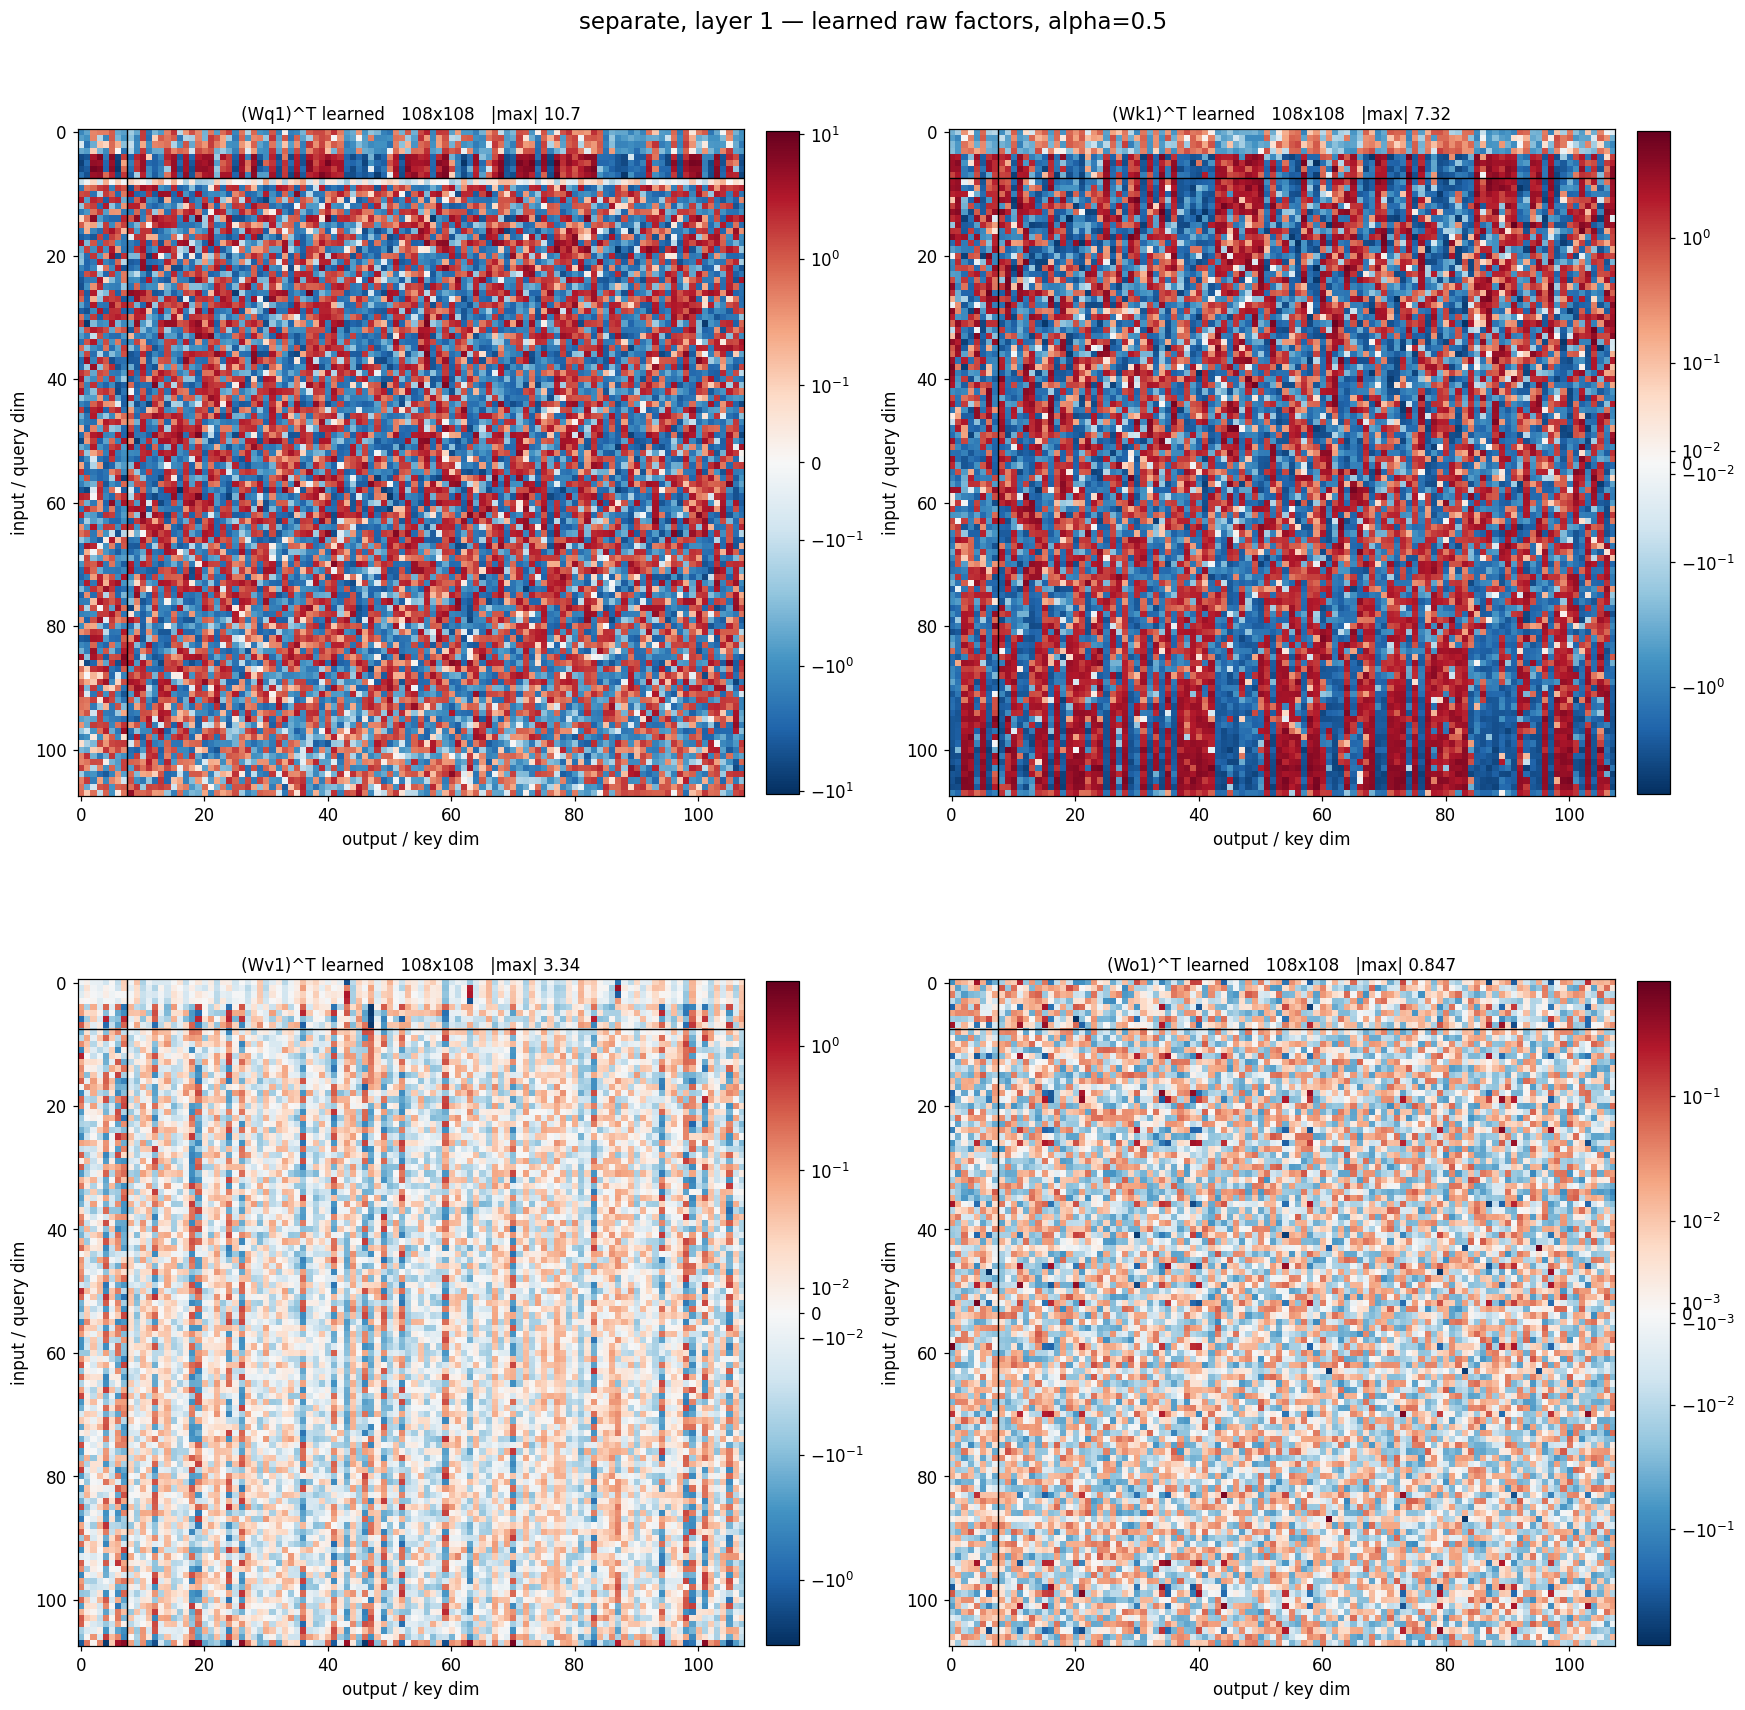

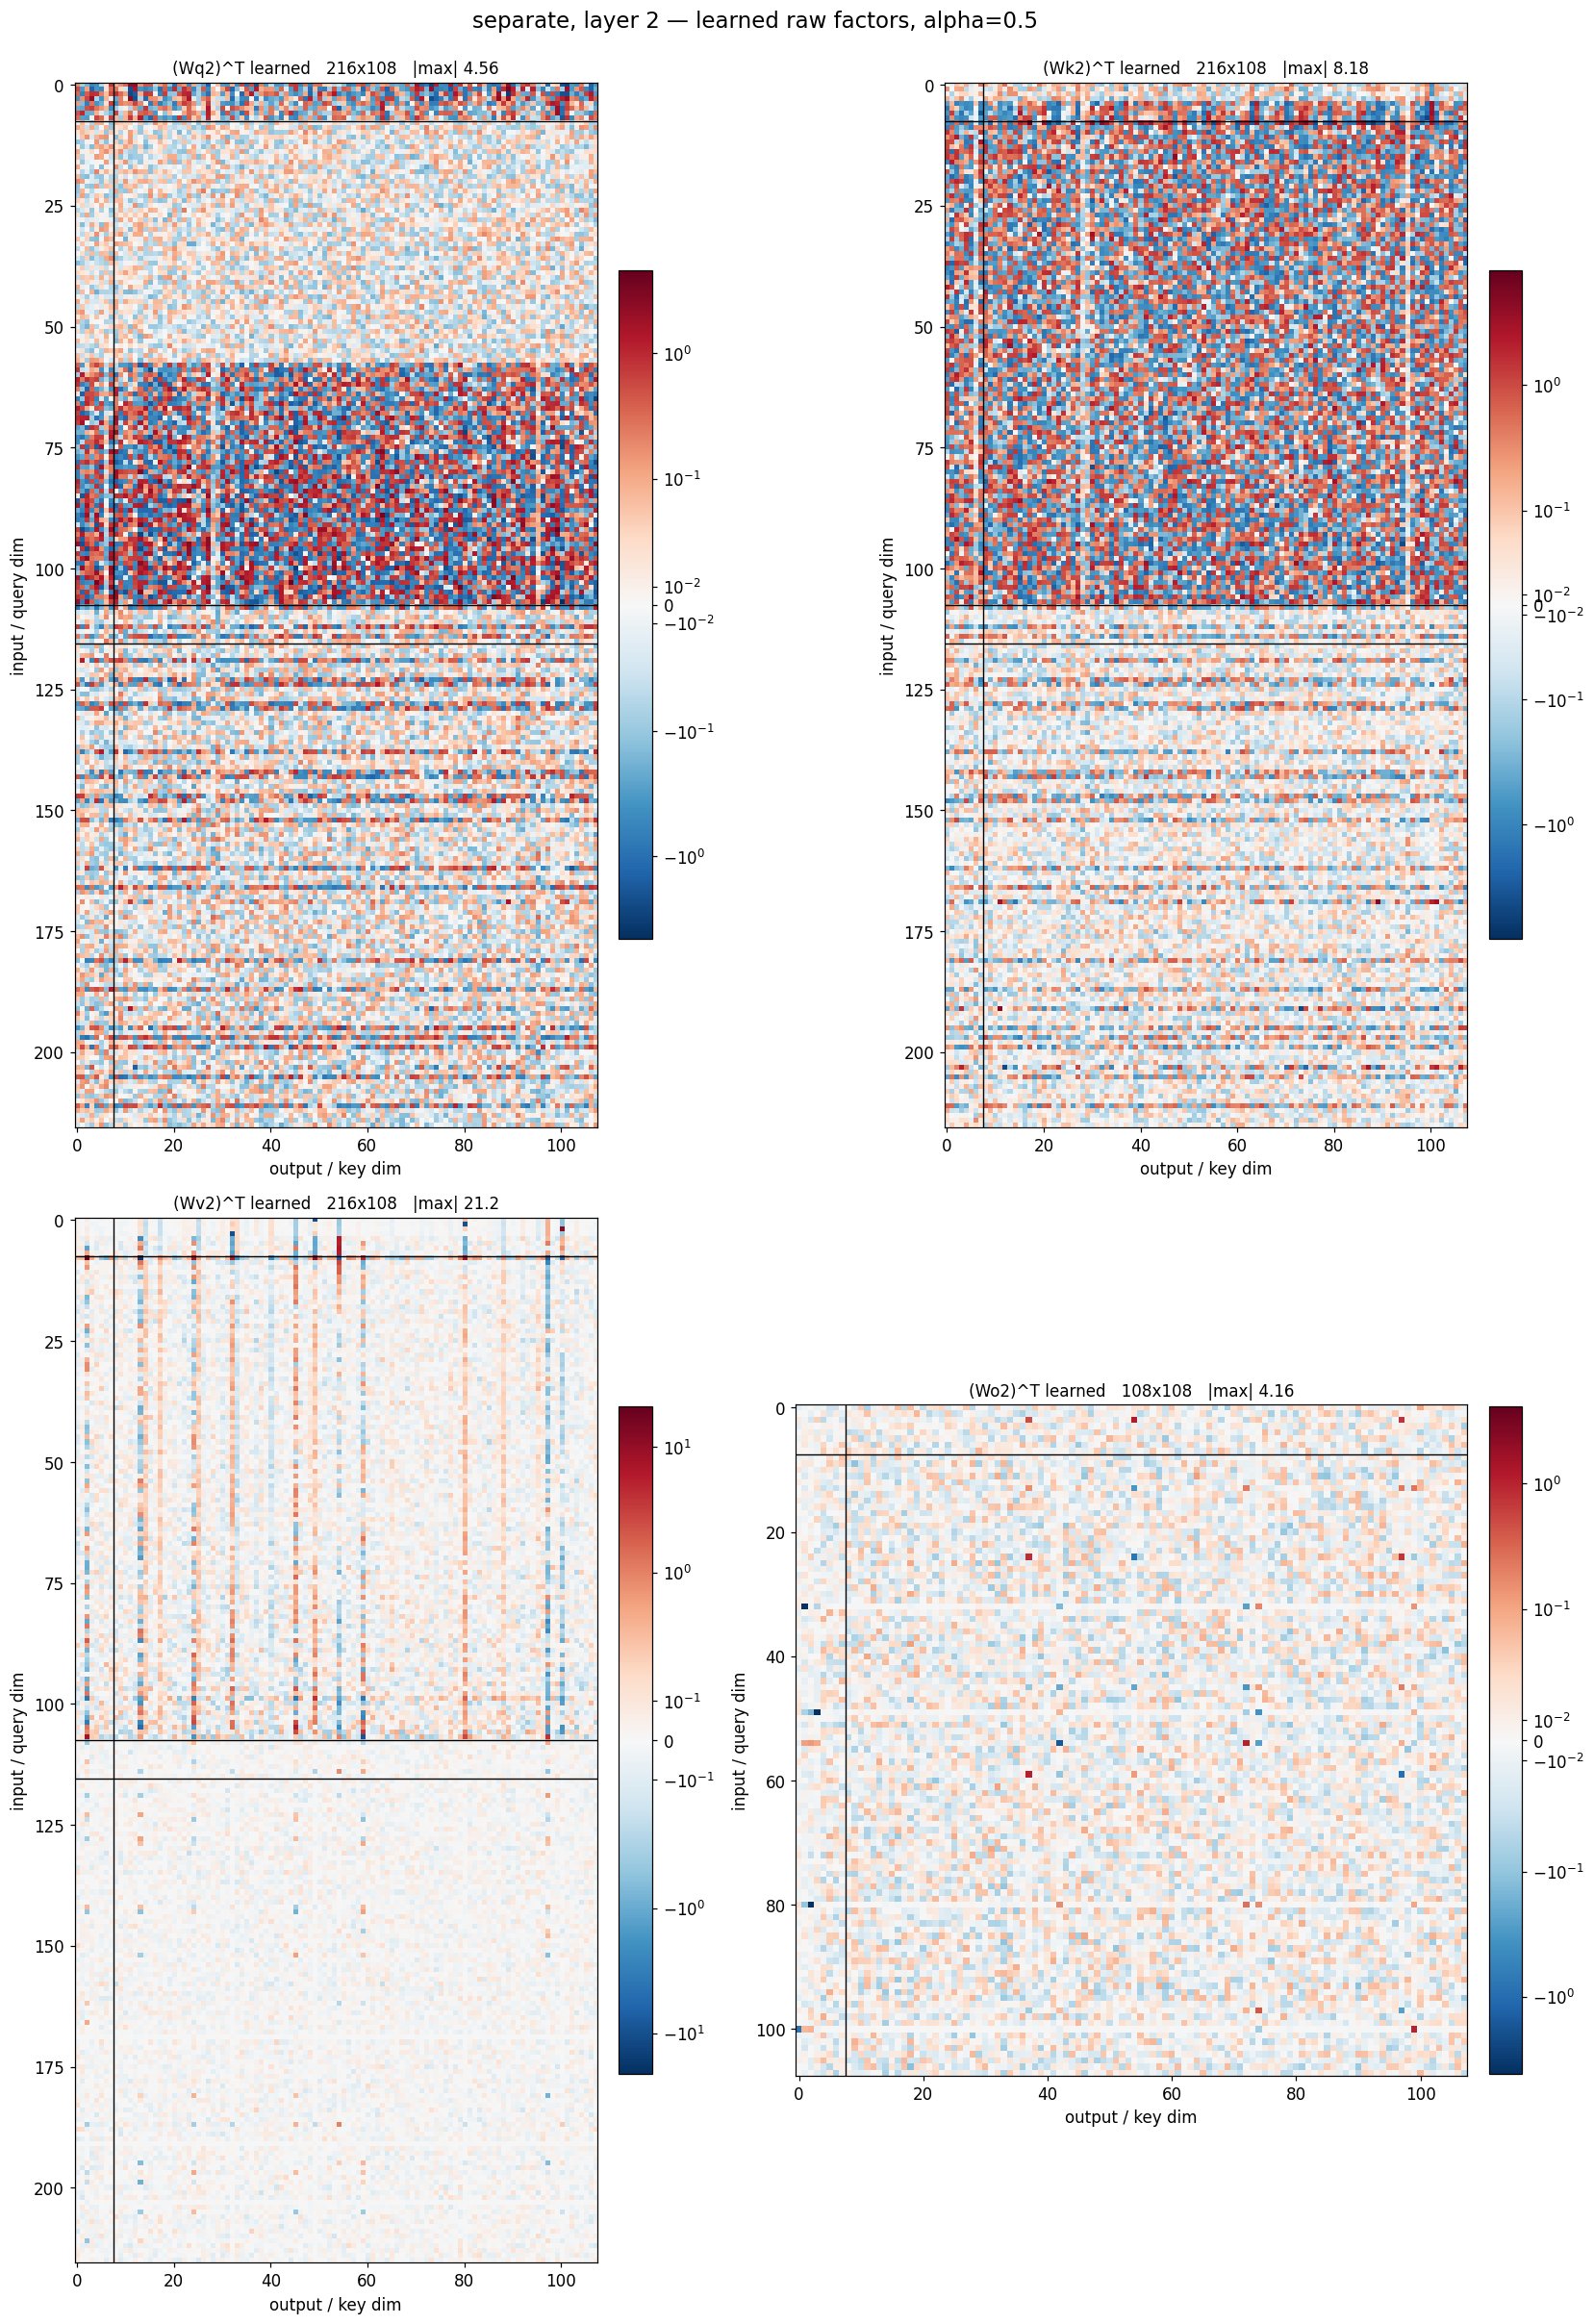

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(16, 16))
for ax, n in zip(axes.ravel(), ['(Wq1)^T learned', '(Wk1)^T learned',
                                '(Wv1)^T learned', '(Wo1)^T learned']):
    im = show(ax, RAWL[n], n)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
fig.suptitle(f'separate, layer 1 — learned raw factors, alpha={THR}', fontsize=15, y=0.995)
fig.tight_layout()
fig.savefig(os.path.join(ART, f'raw_separate_L1_a{THR}.png'), bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(16, 22))
for ax, n in zip(axes.ravel(), ['(Wq2)^T learned', '(Wk2)^T learned',
                                '(Wv2)^T learned', '(Wo2)^T learned']):
    im = show(ax, RAWL[n], n)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
fig.suptitle(f'separate, layer 2 — learned raw factors, alpha={THR}', fontsize=15, y=0.997)
fig.tight_layout()
fig.savefig(os.path.join(ART, f'raw_separate_L2_a{THR}.png'), bbox_inches='tight')
plt.show()


## 3. $W_{qk}$ layer 1 — construction vs learned

The previous-token head. The construction has a dark stripe at **columns 4:8** (never attend to a
noise key), a dark diagonal (never attend to yourself), and an antisymmetric position ramp whose
lower triangle is least-negative right next to the diagonal.


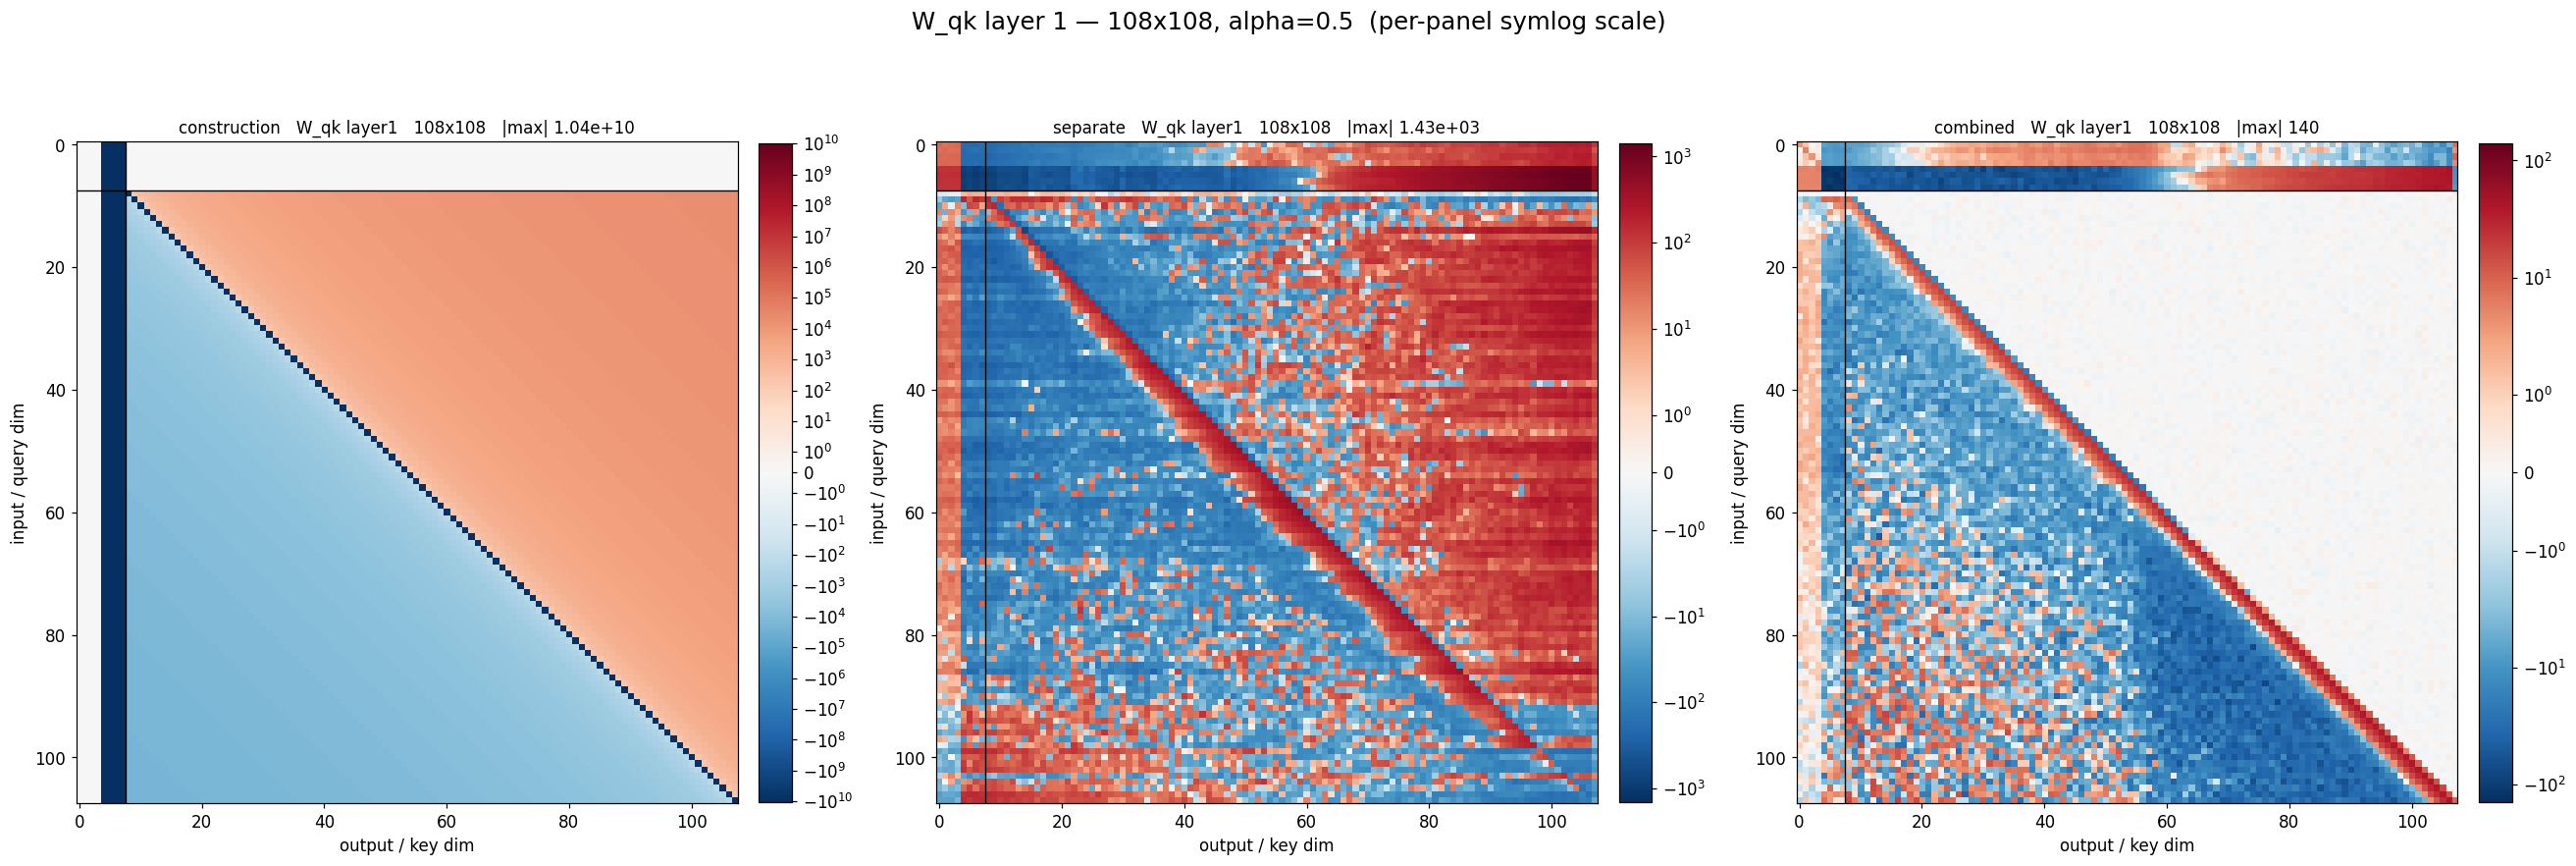

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(24, 8.5))
for ax, (nm, M) in zip(axes, [('construction', PROD['W_qk layer1'])] +
                             [(a, QKL[a][0]) for a in ARCHS]):
    im = show(ax, M, f'{nm}   W_qk layer1')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
fig.suptitle(f'W_qk layer 1 — 108x108, alpha={THR}  (per-panel symlog scale)', fontsize=16)
fig.tight_layout()
fig.savefig(os.path.join(ART, f'wqk1_a{THR}.png'), bbox_inches='tight')
plt.show()


## 4. $W_{ov}$ layer 1 — construction vs learned  *(new: this was frozen before)*

The construction is $I_8$ at `[0:8, 0:8]` and nothing else: copy the attended token's one-hot,
throw the position away. GD has no reason to reproduce that exact matrix — any
$W_{ov}M$ paired with a compensating layer-2 read is equally good — so what to look for is
**which rows carry energy**, not the pattern itself. If the token block 0:8 dominates the position
block 8:108, GD has found the same *information* routing.


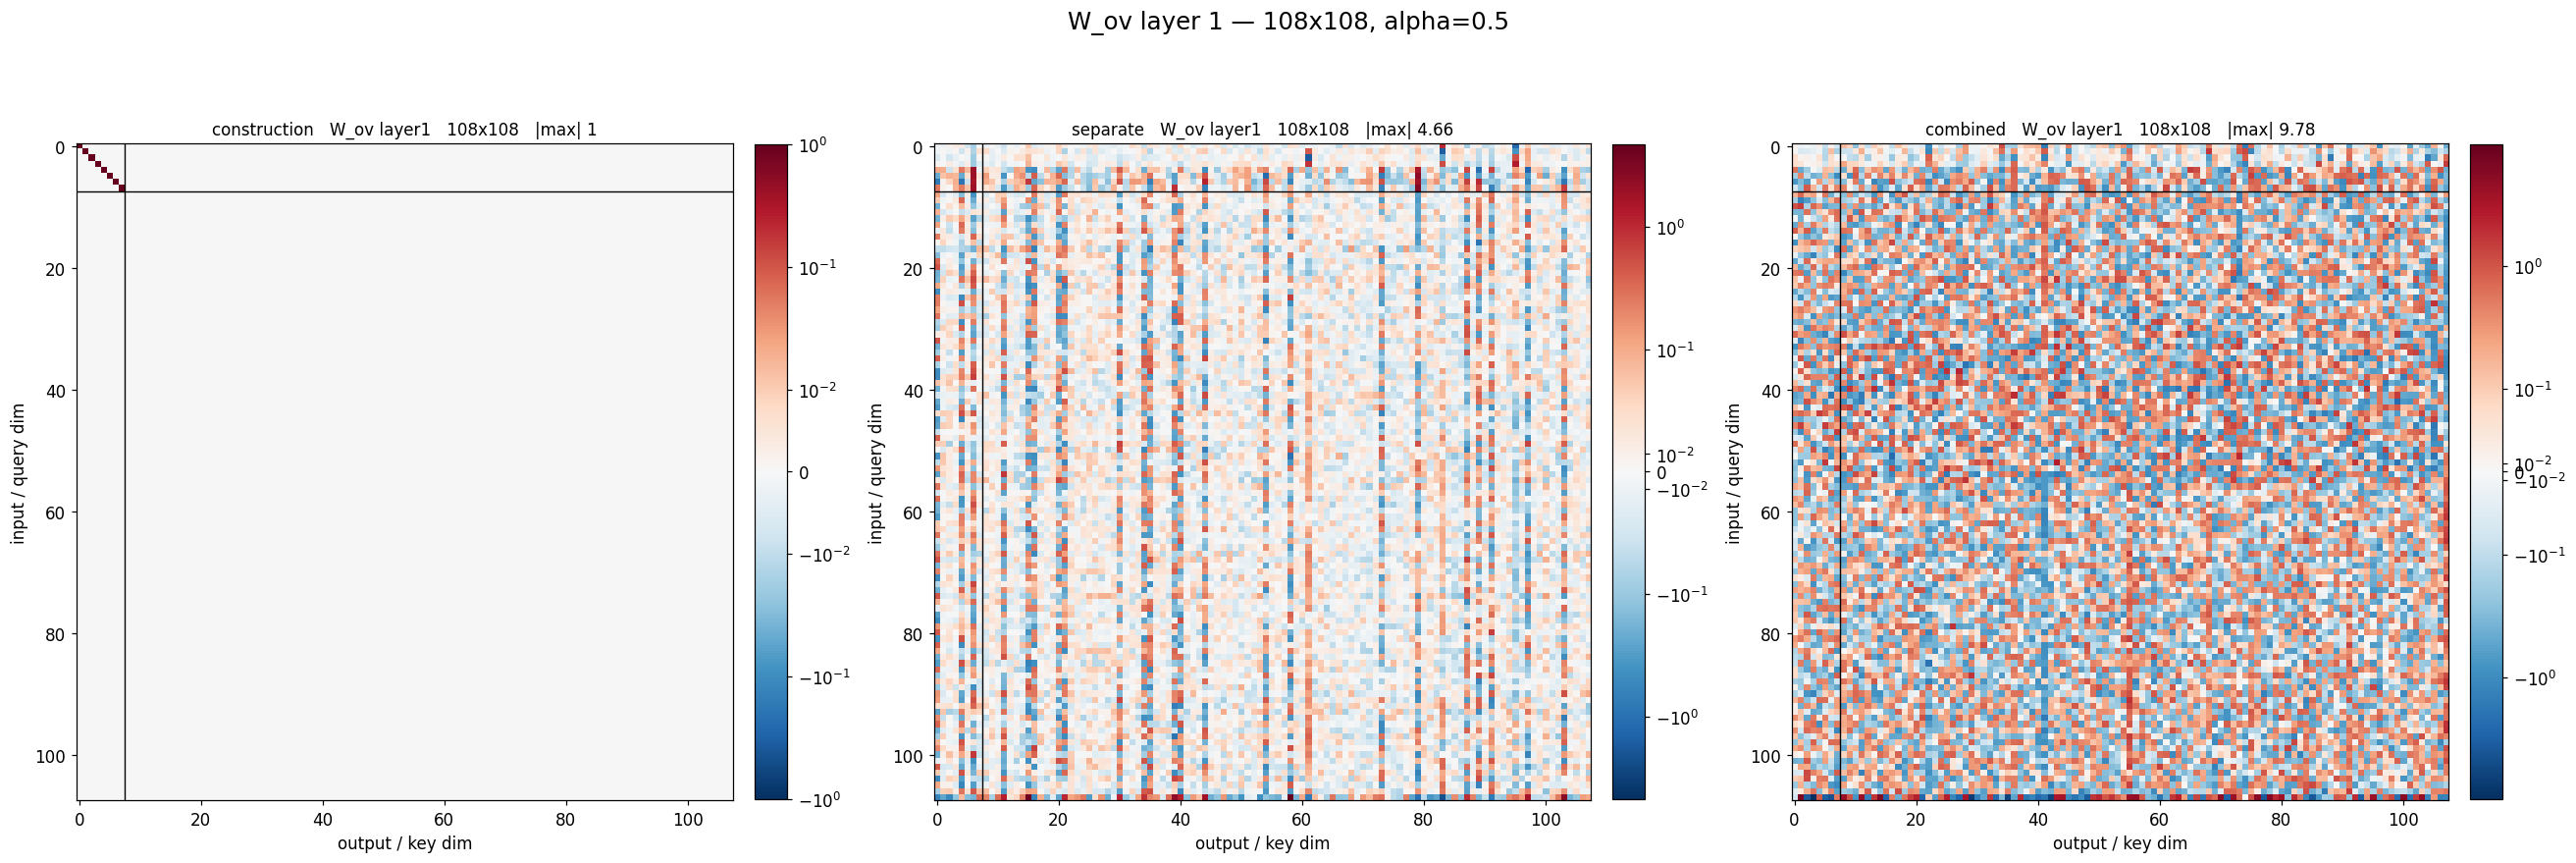

row energy of W_ov layer1, token block 0:8 vs position block 8:108 (construction: 100% token)

arch          ||token rows||_F   ||pos rows||_F  token share
separate                8.1515          14.9279       23.0%
combined               12.5104          57.9144        4.5%
construction            2.8284           0.0000      100.0%


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(24, 8.5))
for ax, (nm, M) in zip(axes, [('construction', PROD['W_ov layer1'])] +
                             [(a, OVL[a][0]) for a in ARCHS]):
    im = show(ax, M, f'{nm}   W_ov layer1')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
fig.suptitle(f'W_ov layer 1 — 108x108, alpha={THR}', fontsize=16)
fig.tight_layout()
fig.savefig(os.path.join(ART, f'wov1_a{THR}.png'), bbox_inches='tight')
plt.show()

print('row energy of W_ov layer1, token block 0:8 vs position block 8:108 '
      '(construction: 100% token)\n')
print(f'{"arch":12s} {"||token rows||_F":>17s} {"||pos rows||_F":>16s} {"token share":>12s}')
for a in ARCHS:
    M = OVL[a][0]
    t, p = float(M[:V].norm()), float(M[V:].norm())
    print(f'{a:12s} {t:17.4f} {p:16.4f} {t**2/(t**2+p**2):11.1%}')
c = PROD['W_ov layer1']
print(f'{"construction":12s} {float(c[:V].norm()):17.4f} {float(c[V:].norm()):16.4f} '
      f'{1.0:11.1%}')


## 5. $W_{qk}$ layer 2 — construction vs learned

The induction match. The construction is 48 non-zeros out of 46,656 cells (0.10%); the learned
matrices are fully dense. Note the rank asymmetry that survives in this parametrization: `combined`
stores an unconstrained $216\times216$, while `separate`'s $W_Q^\top W_K$ is capped at rank 108.


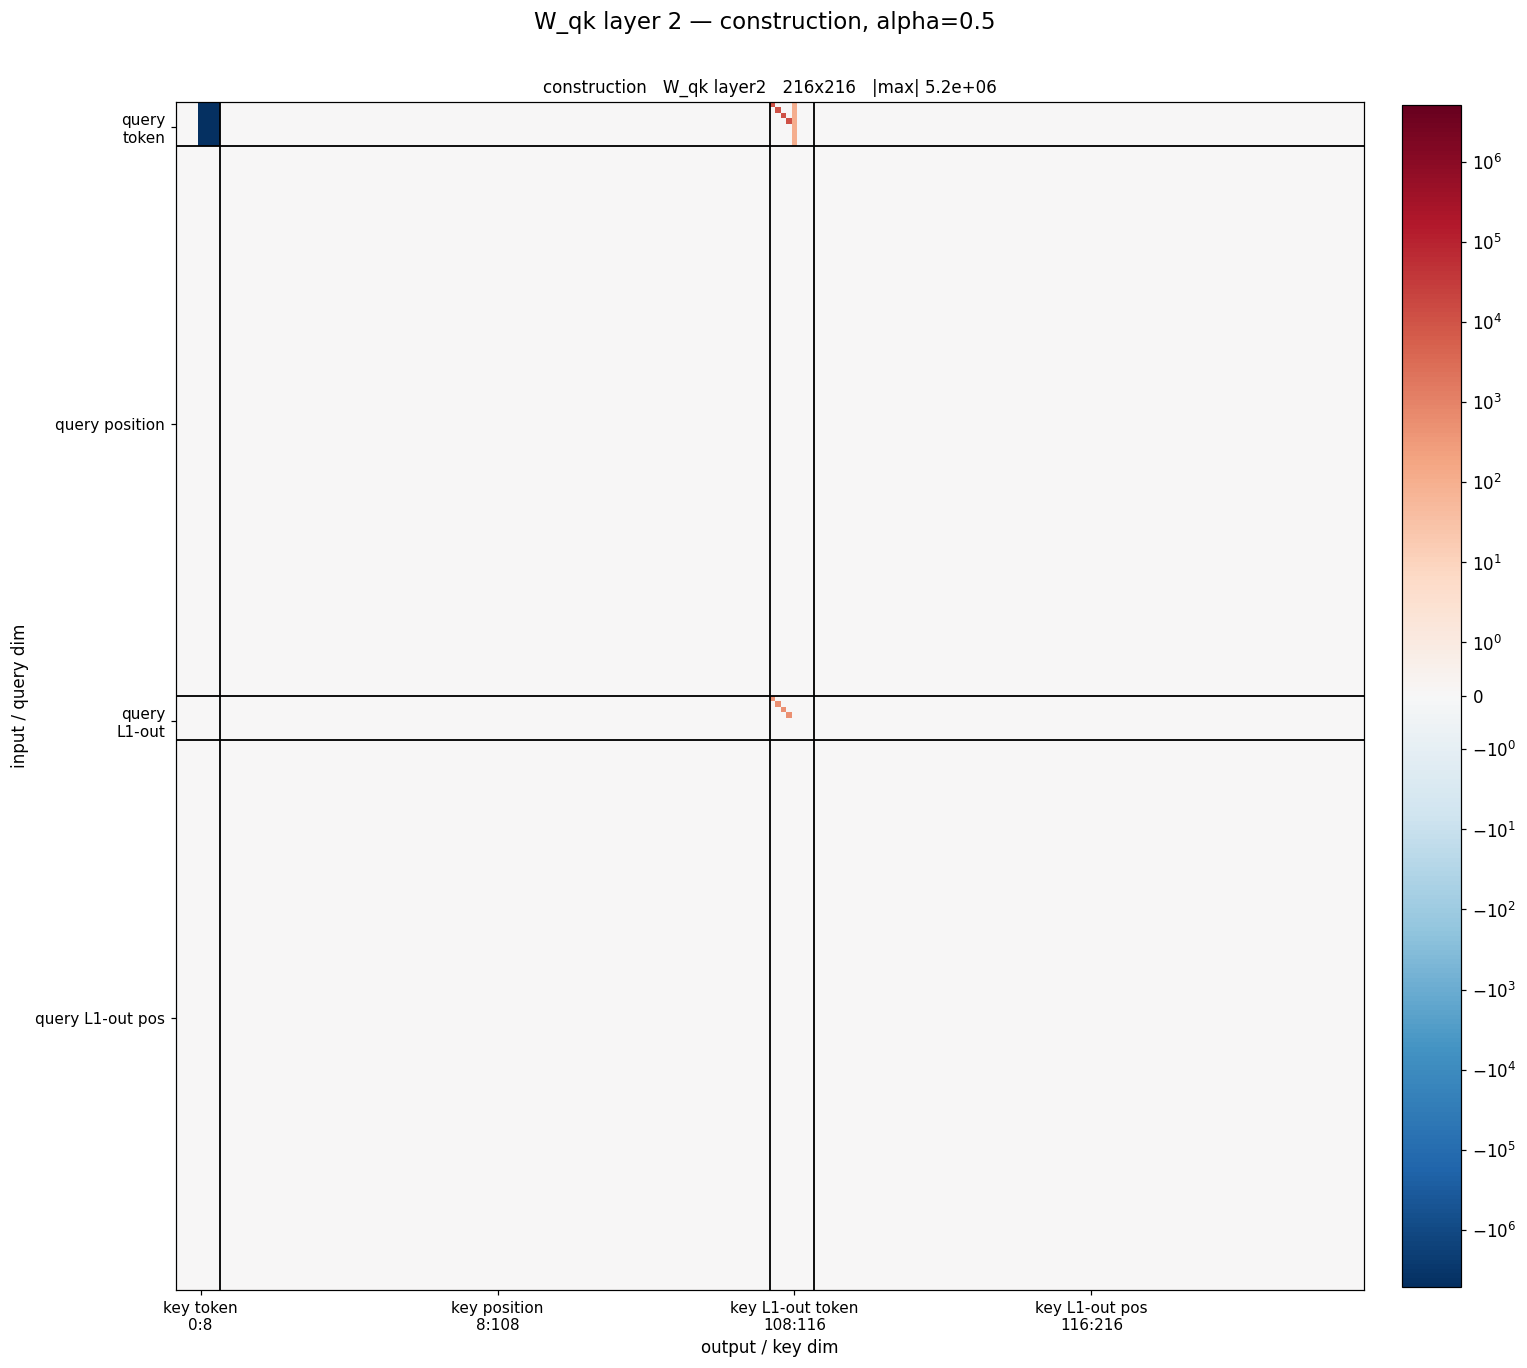

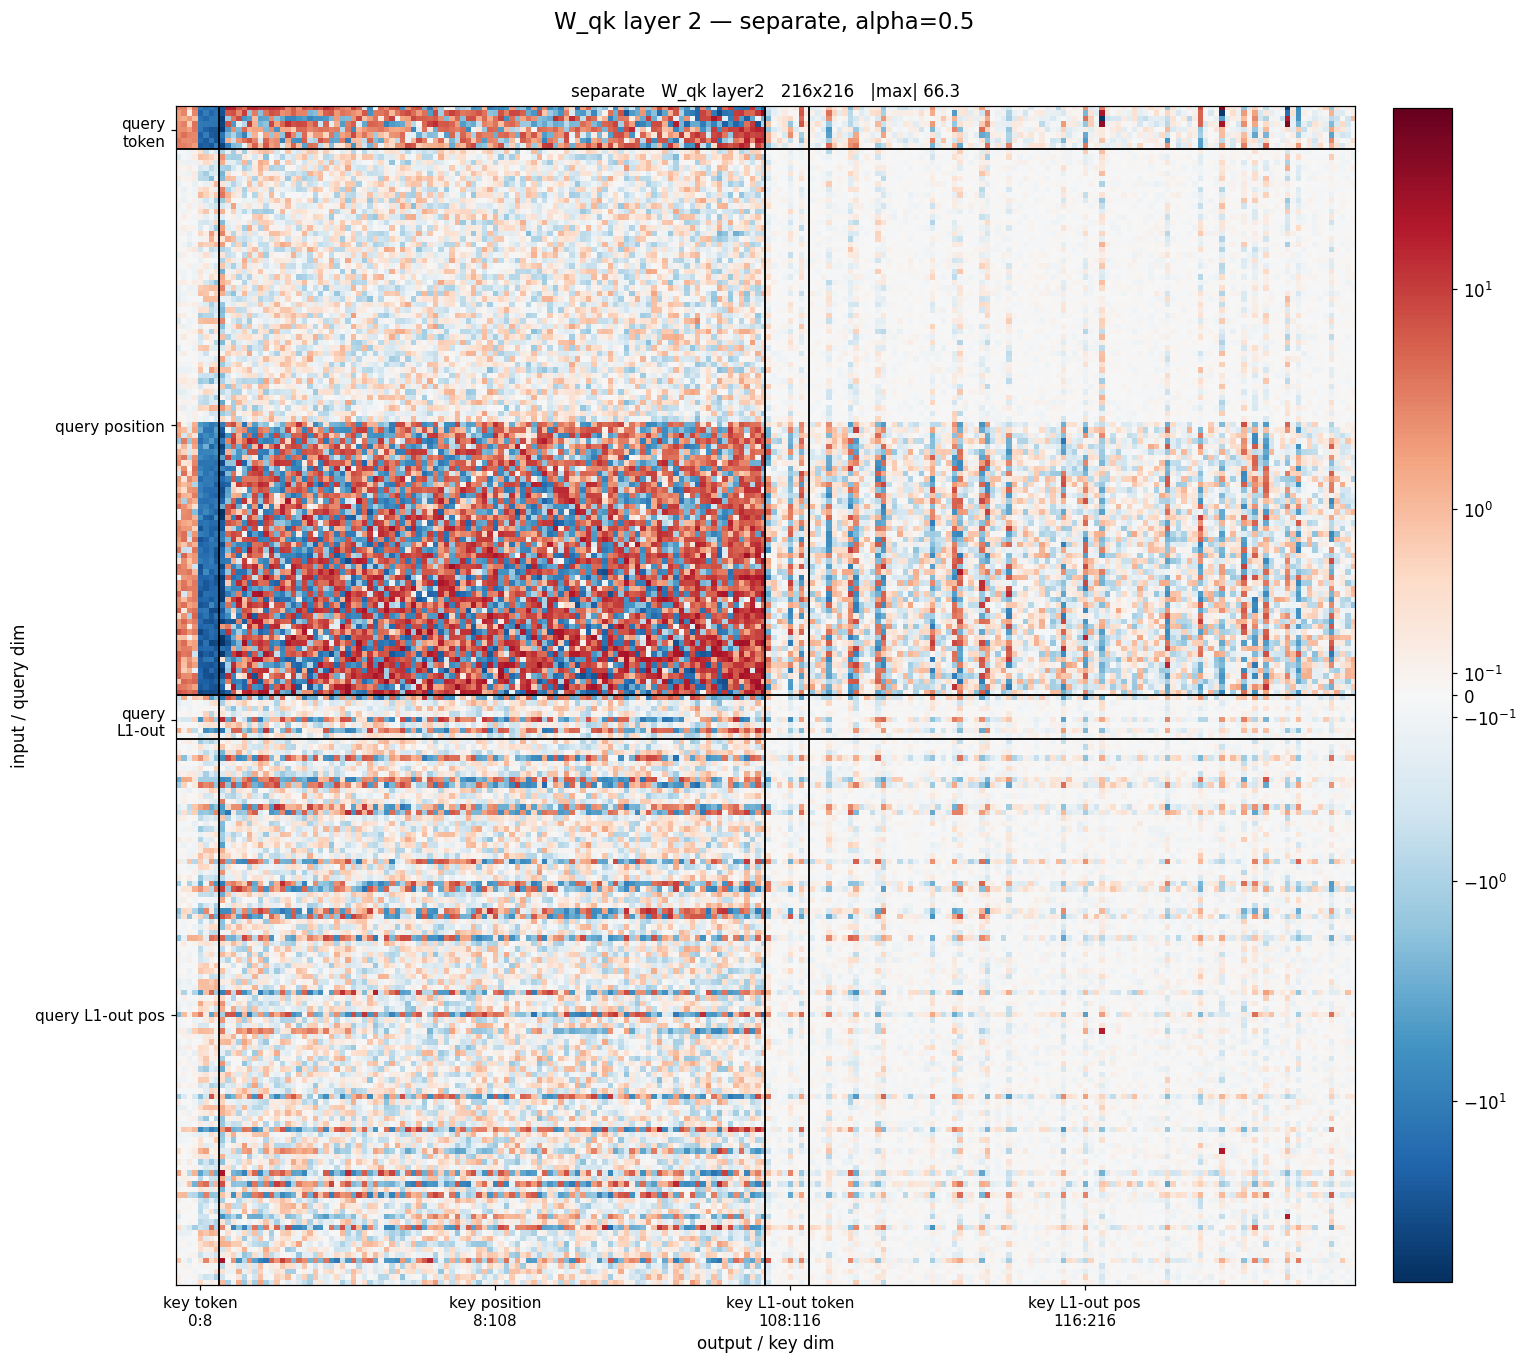

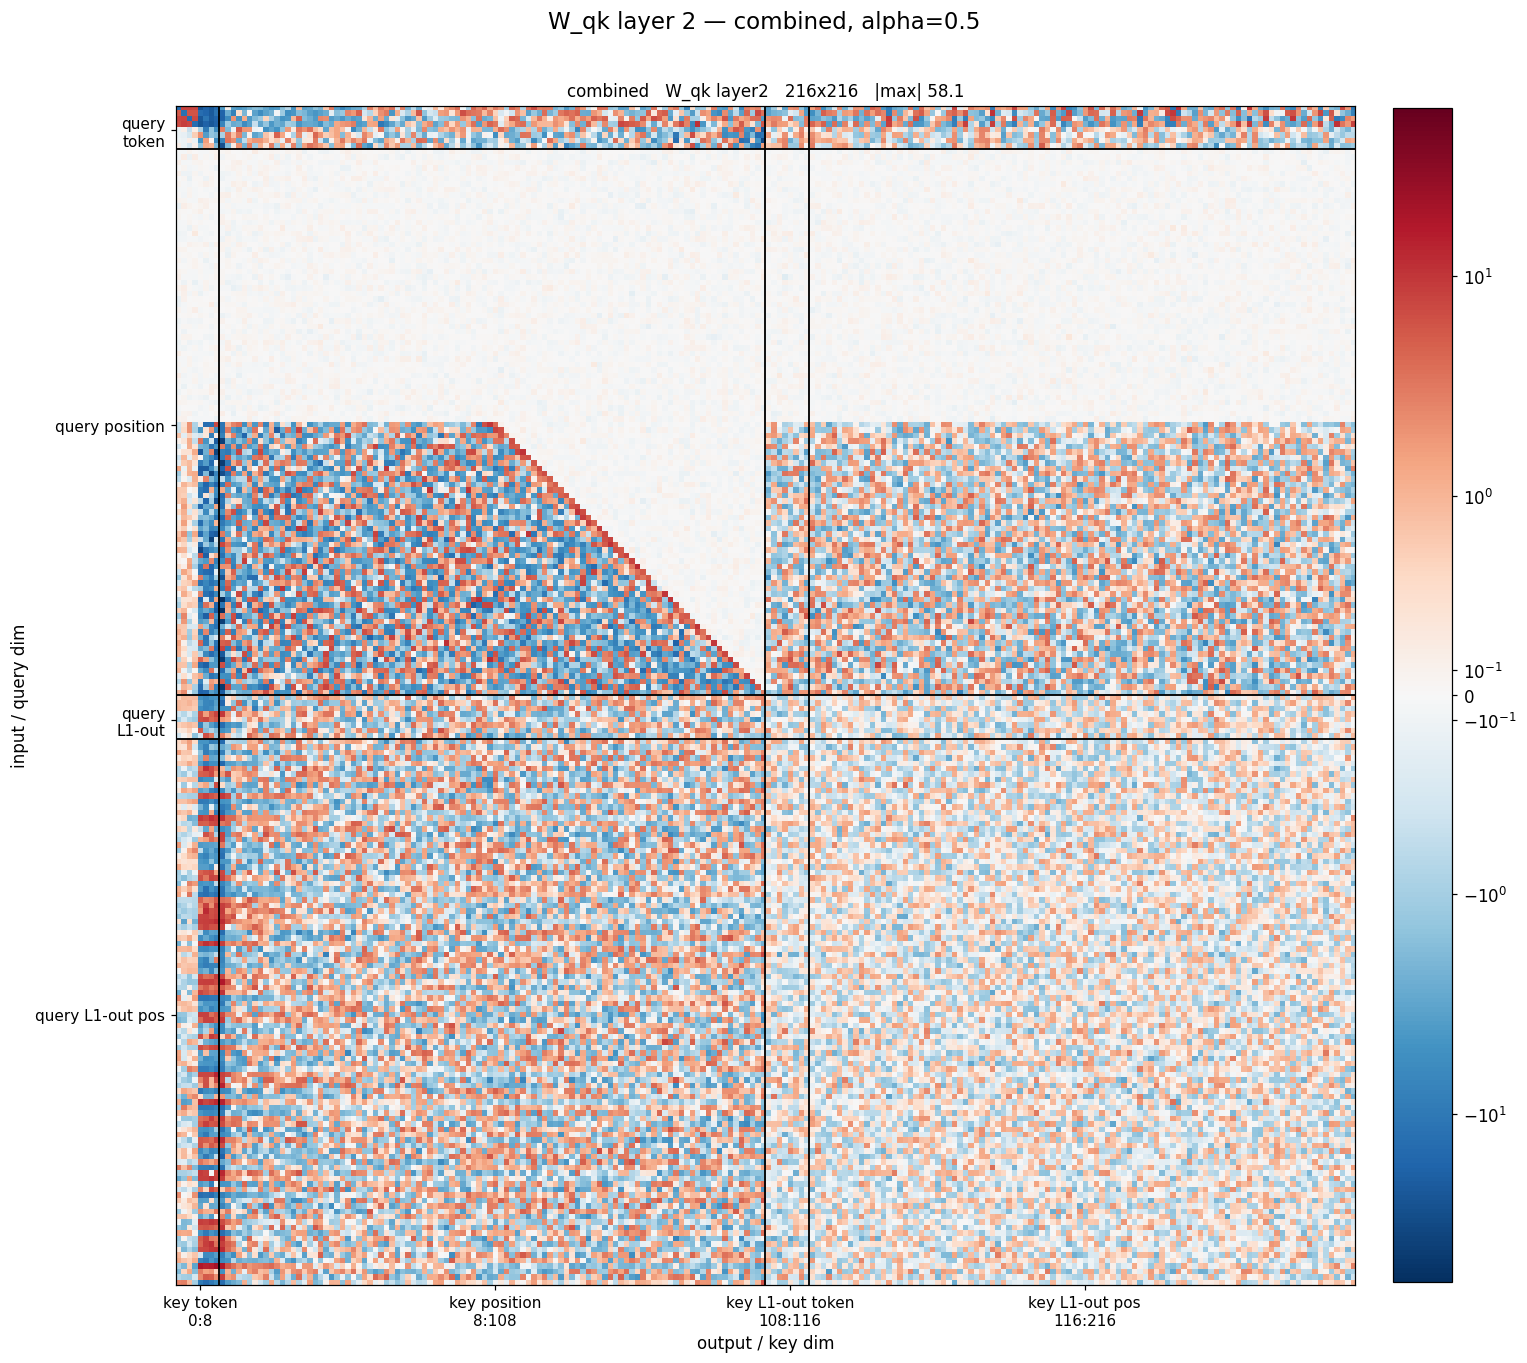

In [7]:
for nm, M in [('construction', PROD['W_qk layer2'])] + [(a, QKL[a][1]) for a in ARCHS]:
    fig, ax = plt.subplots(figsize=(14, 13))
    im = show(ax, M, f'{nm}   W_qk layer2', lw=1.2)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
    ax.set_xticks([V // 2, V + T // 2, D + V // 2, D + V + T // 2])
    ax.set_xticklabels(['key token\n0:8', 'key position\n8:108',
                        'key L1-out token\n108:116', 'key L1-out pos\n116:216'], fontsize=10)
    ax.set_yticks([V // 2, V + T // 2, D + V // 2, D + V + T // 2])
    ax.set_yticklabels(['query\ntoken', 'query position', 'query\nL1-out',
                        'query L1-out pos'], fontsize=10)
    fig.suptitle(f'W_qk layer 2 — {nm}, alpha={THR}', fontsize=15)
    fig.tight_layout()
    fig.savefig(os.path.join(ART, f'wqk2_{nm}_a{THR}.png'), bbox_inches='tight')
    plt.show()


## 6. $W_{ov}$ layer 2 — construction vs learned  *(new: this was frozen before)*

216 rows in, 108 out. The construction is again $I_8$ at `[0:8, 0:8]`: write the attended
position's own token one-hot into the eight count slots, and nothing anywhere else. Under the
relaxed run these 108 output coordinates are an arbitrary basis, so read the row-block energy
(does the query's **own token block** 0:8 dominate?) rather than the cells.


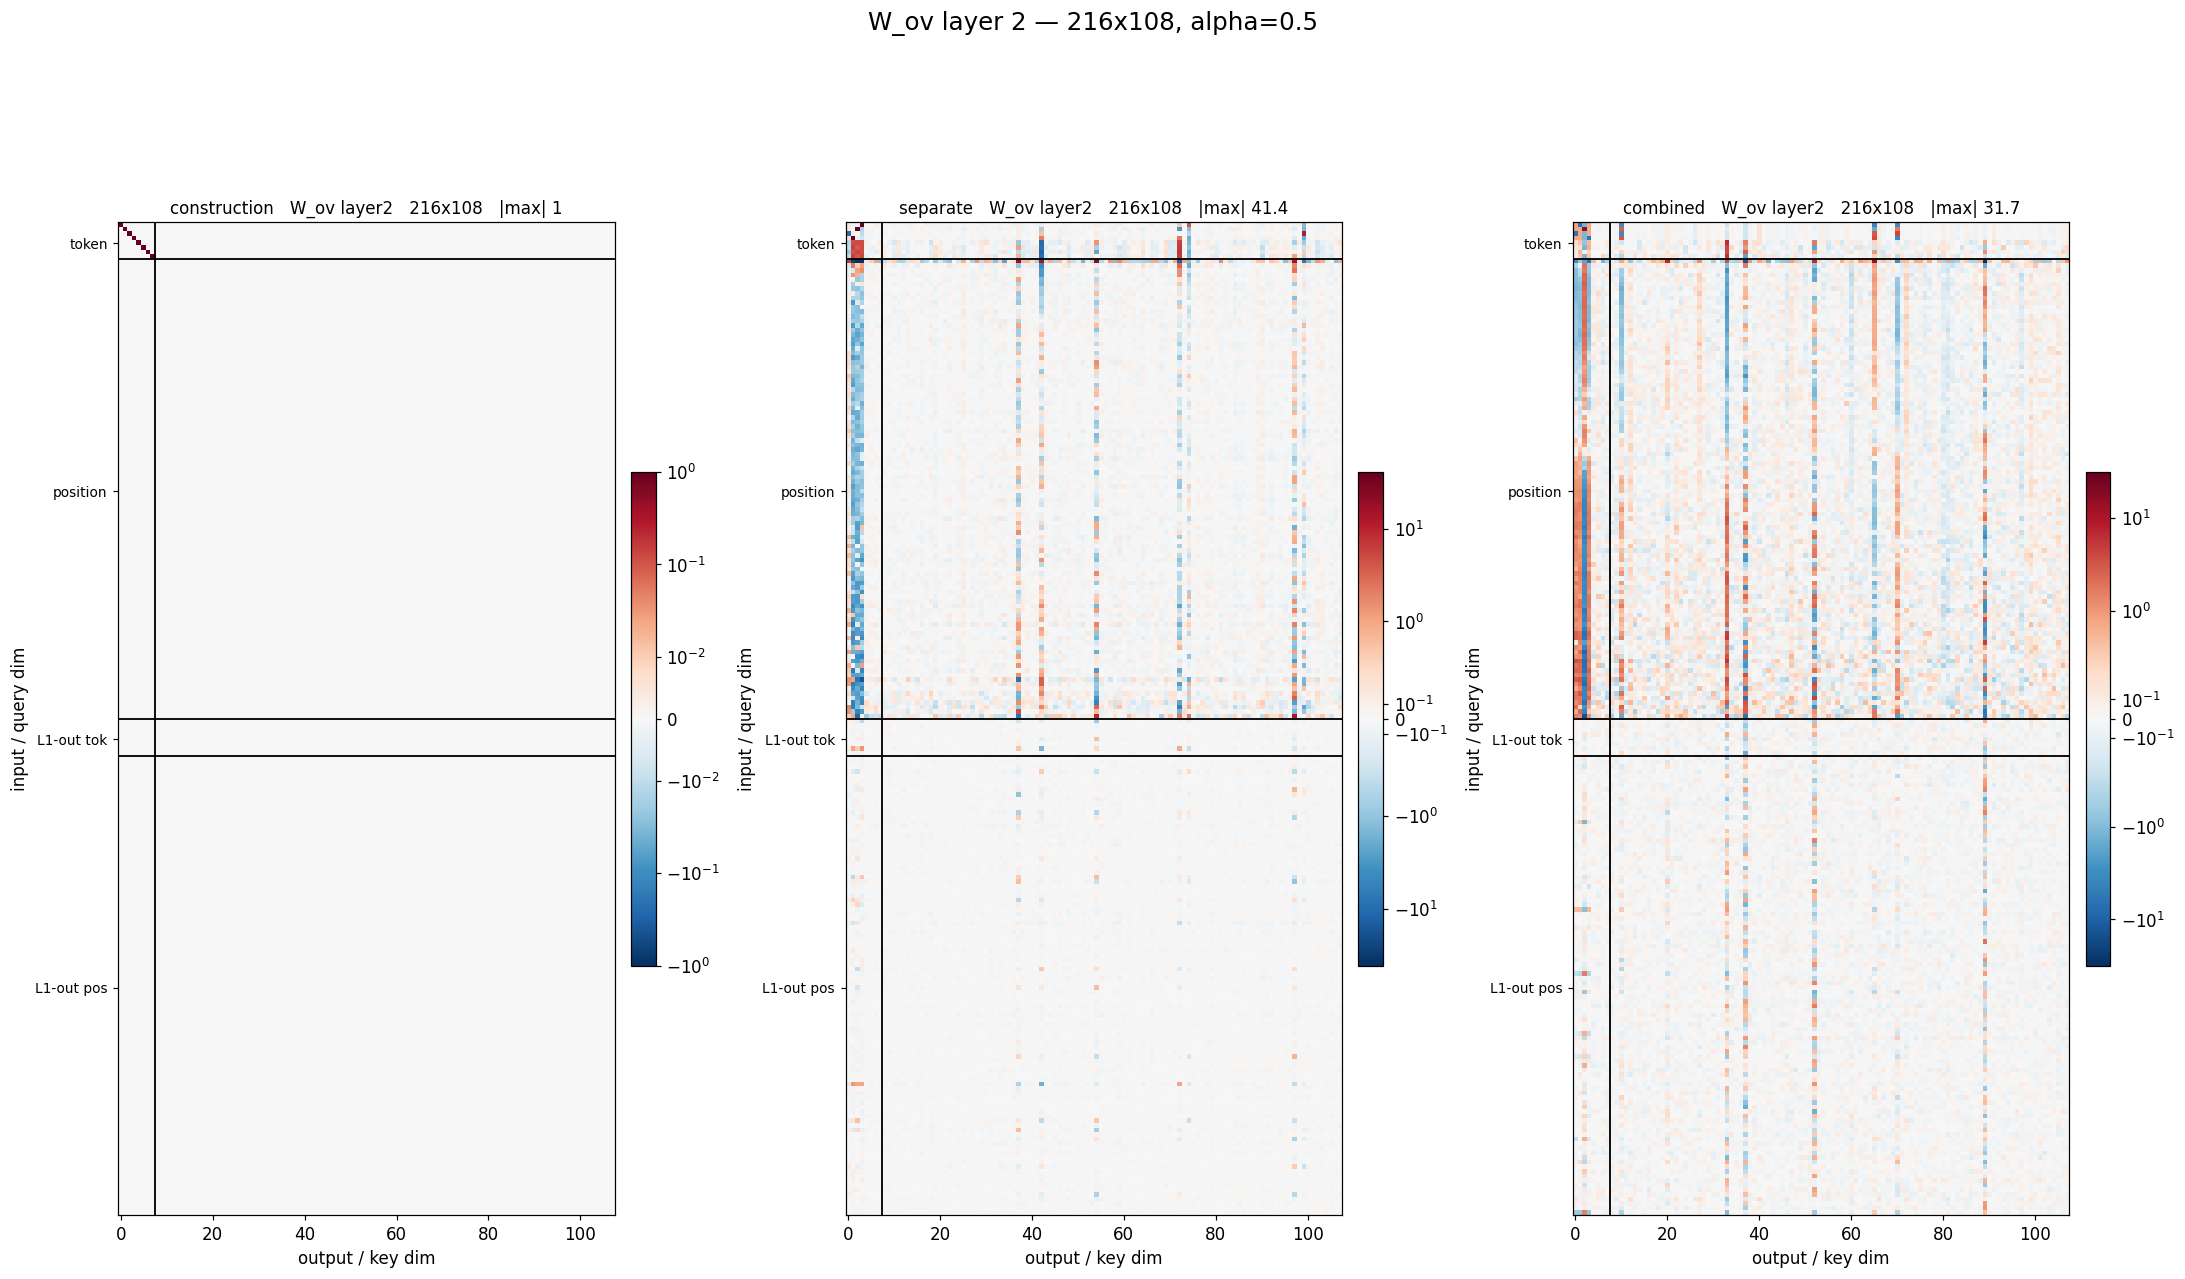

row-block energy of W_ov layer2 (construction: 100% in the own-token block 0:8)

arch                     token 0:8        position 8:108  L1-out token 108:116    L1-out pos 116:216
construction               100.0%                  0.0%                  0.0%                  0.0% 
separate                    43.7%                 56.0%                  0.1%                  0.2% 
combined                    11.8%                 85.4%                  0.2%                  2.6% 


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(20, 13))
for ax, (nm, M) in zip(axes, [('construction', PROD['W_ov layer2'])] +
                             [(a, OVL[a][1]) for a in ARCHS]):
    im = show(ax, M, f'{nm}   W_ov layer2', lw=1.2)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
    ax.set_yticks([V // 2, V + T // 2, D + V // 2, D + V + T // 2])
    ax.set_yticklabels(['token', 'position', 'L1-out tok', 'L1-out pos'], fontsize=9)
fig.suptitle(f'W_ov layer 2 — 216x108, alpha={THR}', fontsize=16)
fig.tight_layout()
fig.savefig(os.path.join(ART, f'wov2_a{THR}.png'), bbox_inches='tight')
plt.show()

print('row-block energy of W_ov layer2 (construction: 100% in the own-token block 0:8)\n')
blocks = [('token 0:8', 0, V), ('position 8:108', V, D),
          ('L1-out token 108:116', D, D + V), ('L1-out pos 116:216', D + V, IN2)]
hdr = ''.join(f'{b[0]:>22s}' for b in blocks)
print(f'{"arch":12s}{hdr}')
for nm, M in [('construction', PROD['W_ov layer2'])] + [(a, OVL[a][1]) for a in ARCHS]:
    e = [float(M[r0:r1].norm()) ** 2 for _, r0, r1 in blocks]
    tot = sum(e) or 1.0
    print(f'{nm:12s}' + ''.join(f'{x/tot:>21.1%} ' for x in e))


## 7. Annotated close-ups — every cell value printed

The same four blocks as the construction notebook, construction in the left column. The one that
matters is **L2 own token $\times$ key predecessor**: its $4\times4$ diagonal is the induction
match, and it has to stand out from its own off-diagonal for the head to work.


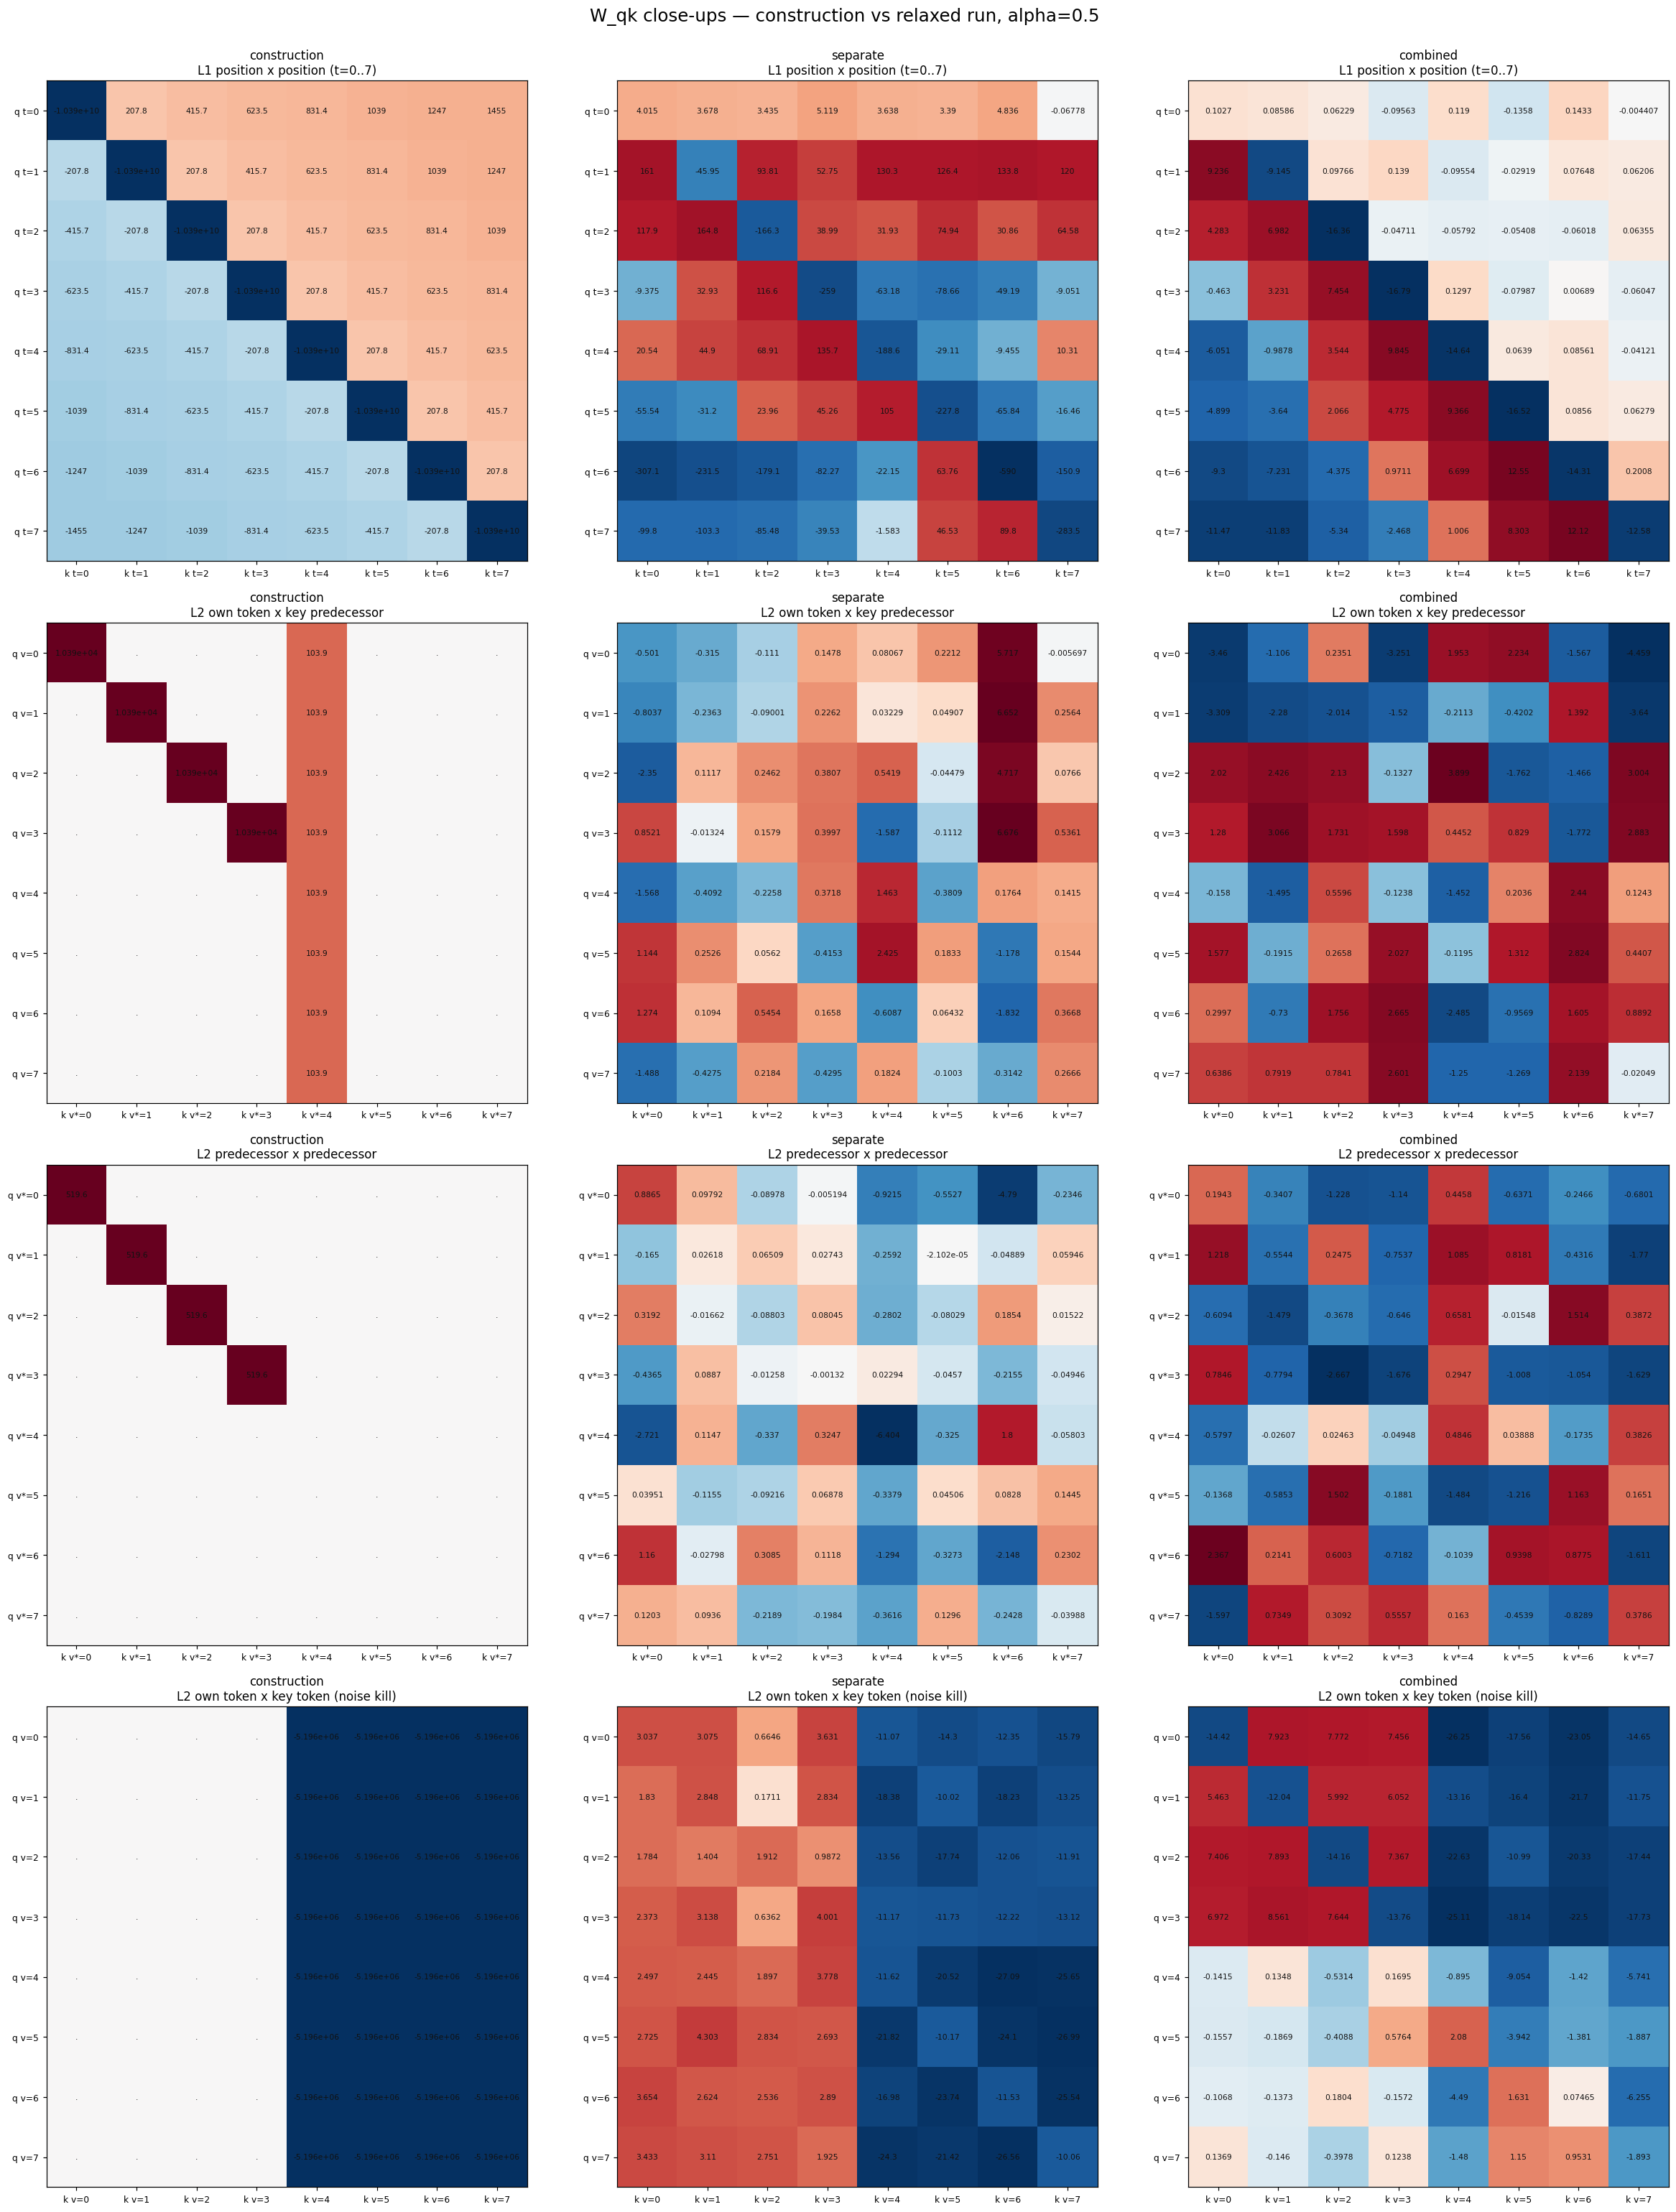

In [9]:
BLOCKS = [('L1 position x position (t=0..7)', 'W_qk layer1', 0, V, V + 8, V, V + 8,
           [f'q t={i}' for i in range(8)], [f'k t={i}' for i in range(8)]),
          ('L2 own token x key predecessor', 'W_qk layer2', 1, 0, V, D, D + V,
           [f'q v={i}' for i in range(V)], [f'k v*={i}' for i in range(V)]),
          ('L2 predecessor x predecessor', 'W_qk layer2', 1, D, D + V, D, D + V,
           [f'q v*={i}' for i in range(V)], [f'k v*={i}' for i in range(V)]),
          ('L2 own token x key token (noise kill)', 'W_qk layer2', 1, 0, V, 0, V,
           [f'q v={i}' for i in range(V)], [f'k v={i}' for i in range(V)])]

fig, axes = plt.subplots(len(BLOCKS), 3, figsize=(22, 7.0 * len(BLOCKS)))
for r, (title, key, li, r0, r1, c0, c1, rlab, clab) in enumerate(BLOCKS):
    for c, (nm, M) in enumerate([('construction', PROD[key])] +
                                [(a, QKL[a][li]) for a in ARCHS]):
        annot(axes[r][c], M, r0, r1, c0, c1, f'{nm}\n{title}', rlab=rlab, clab=clab, fs=7)
fig.suptitle(f'W_qk close-ups — construction vs relaxed run, alpha={THR}', fontsize=16, y=0.999)
fig.tight_layout()
fig.savefig(os.path.join(ART, f'closeups_wqk_a{THR}.png'), bbox_inches='tight')
plt.show()


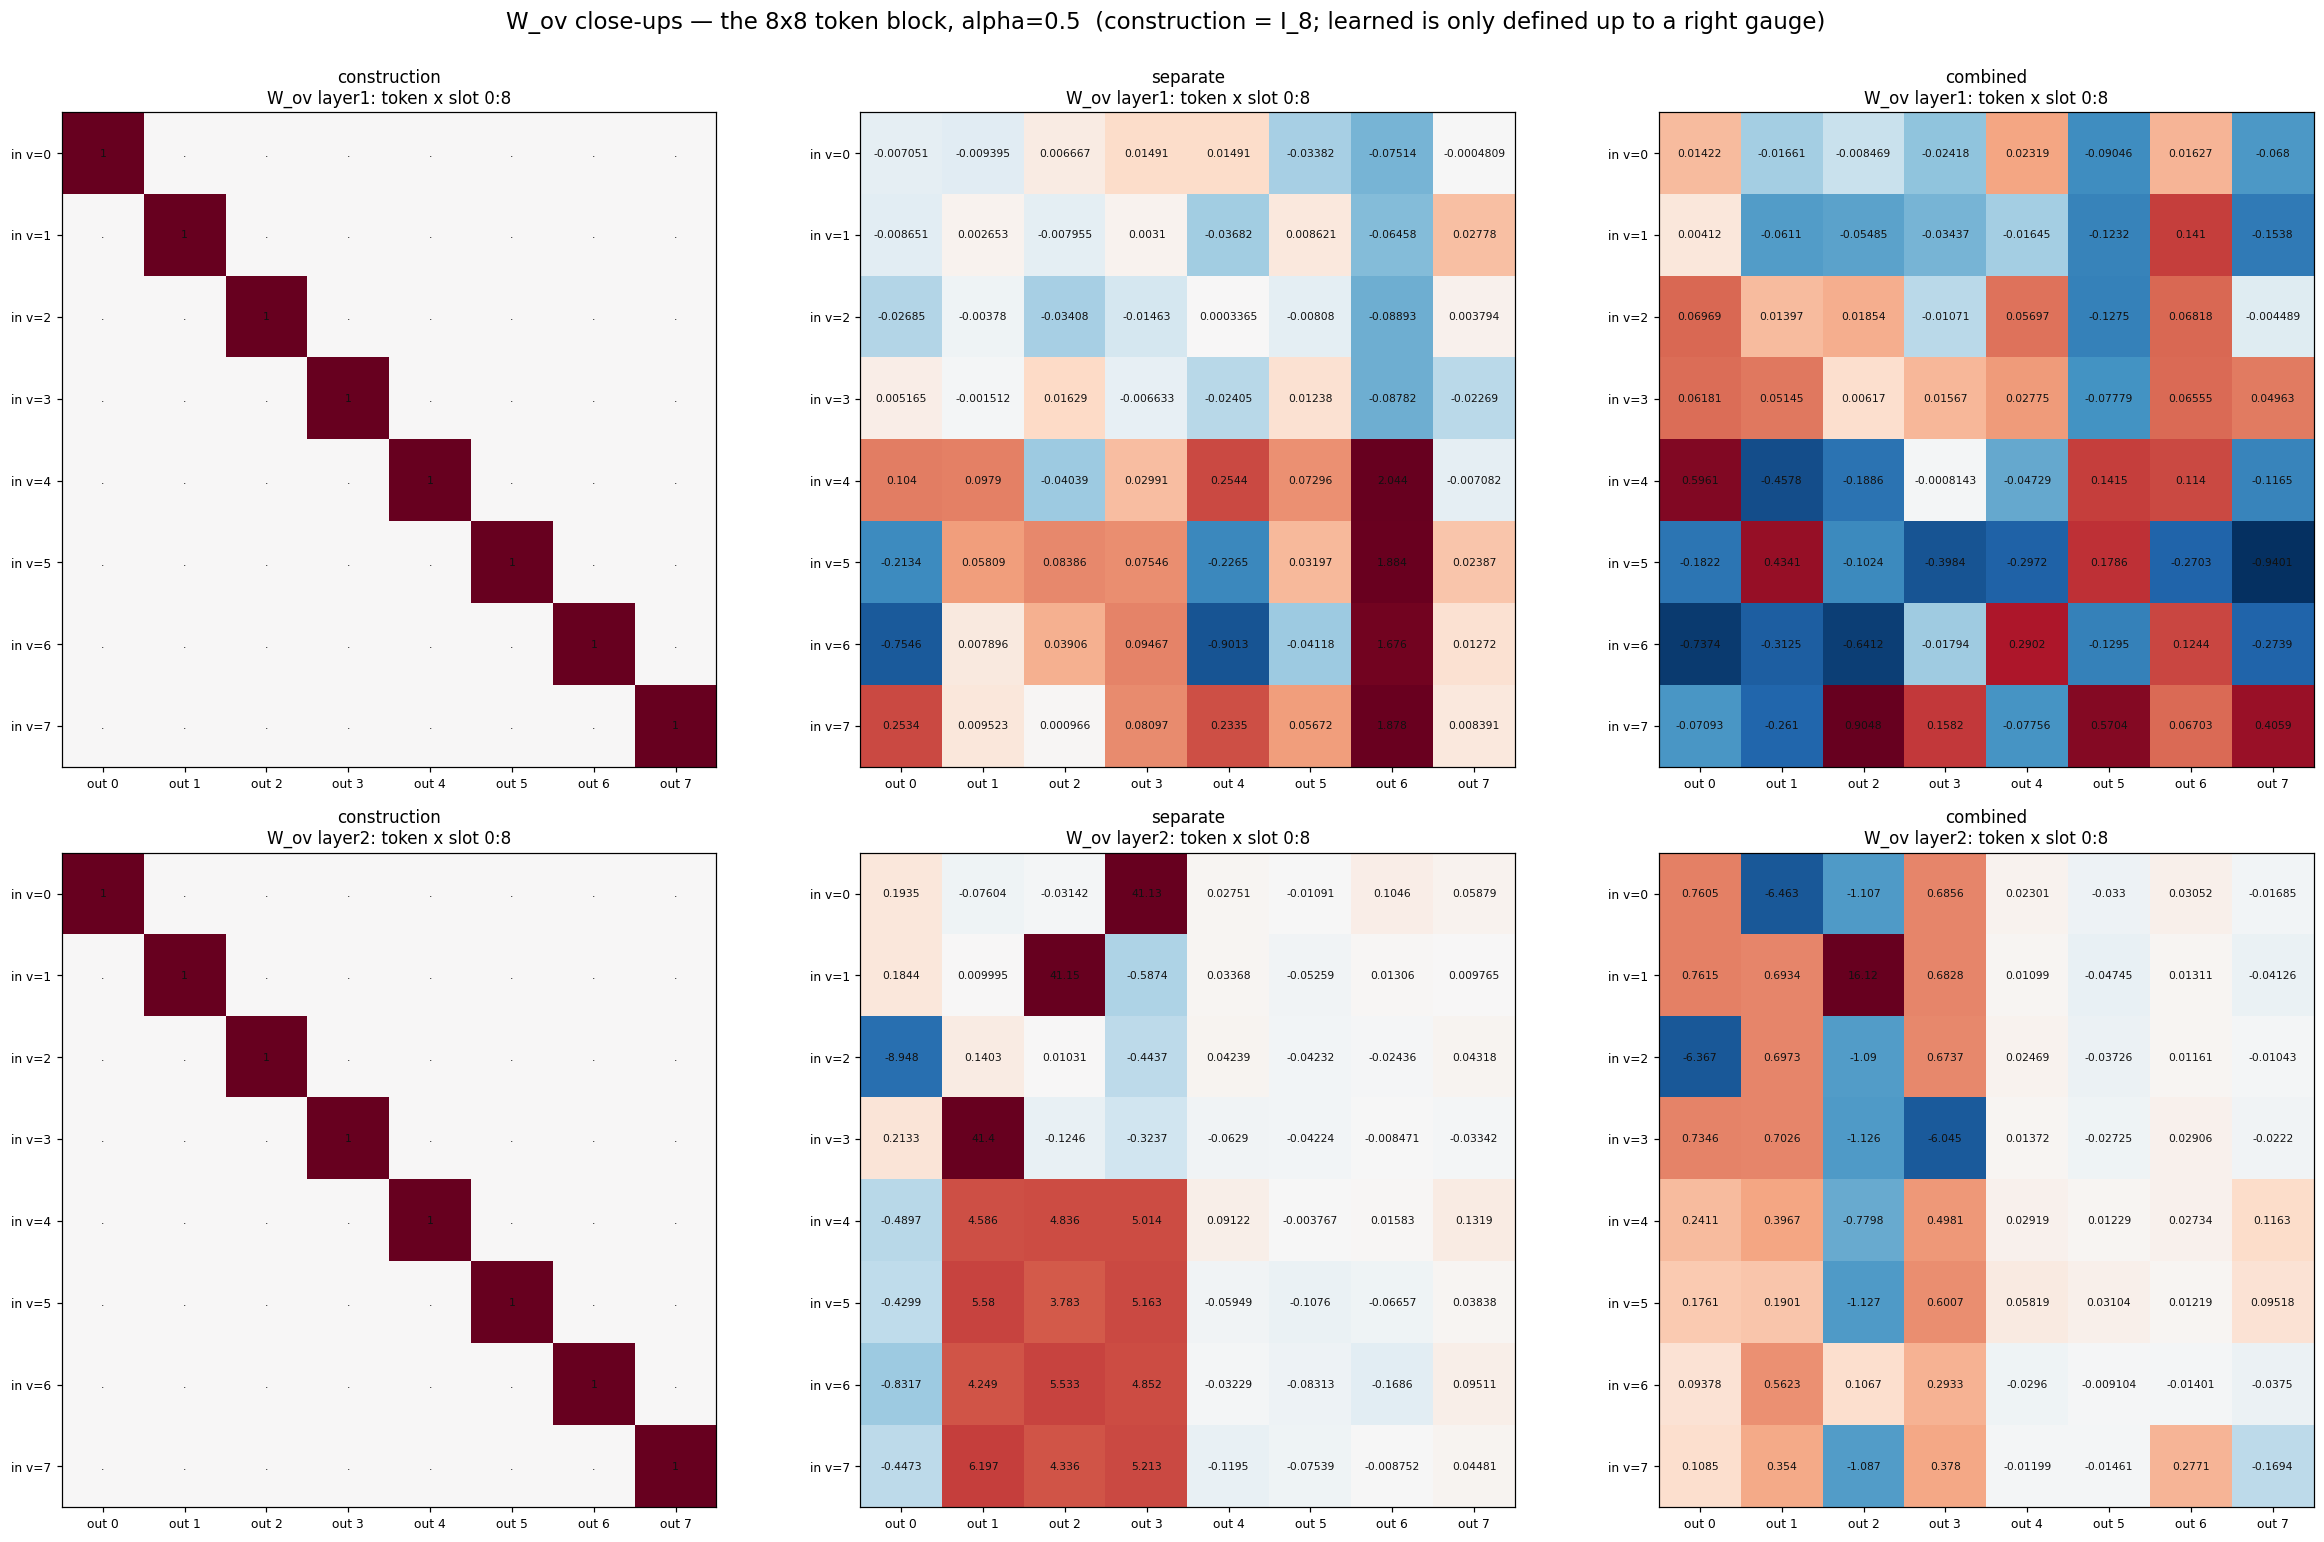

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(22, 14))
for r, (key, li) in enumerate([('W_ov layer1', 0), ('W_ov layer2', 1)]):
    for c, (nm, M) in enumerate([('construction', PROD[key])] +
                                [(a, OVL[a][li]) for a in ARCHS]):
        annot(axes[r][c], M, 0, V, 0, V, f'{nm}\n{key}: token x slot 0:8',
              rlab=[f'in v={i}' for i in range(V)], clab=[f'out {i}' for i in range(V)], fs=7)
fig.suptitle(f'W_ov close-ups — the 8x8 token block, alpha={THR}  '
             '(construction = I_8; learned is only defined up to a right gauge)',
             fontsize=15, y=0.999)
fig.tight_layout()
fig.savefig(os.path.join(ART, f'closeups_wov_a{THR}.png'), bbox_inches='tight')
plt.show()


## 8. The unembedding — the third thing that was frozen before

`fc_out` is $8\times324$ plus an 8-vector bias. The construction pins it to the identity selector
that reads only the eight layer-2 count slots (columns 216:224) with weight 1 and no bias.

The relaxed run has to find that selector itself, and it also has 316 other columns it *could*
read — the raw token one-hot, position, the layer-1 output. The first plot is the full matrix; the
second is the column-block energy, which answers the actual question: **does GD learn to read the
count slots and ignore everything else?**


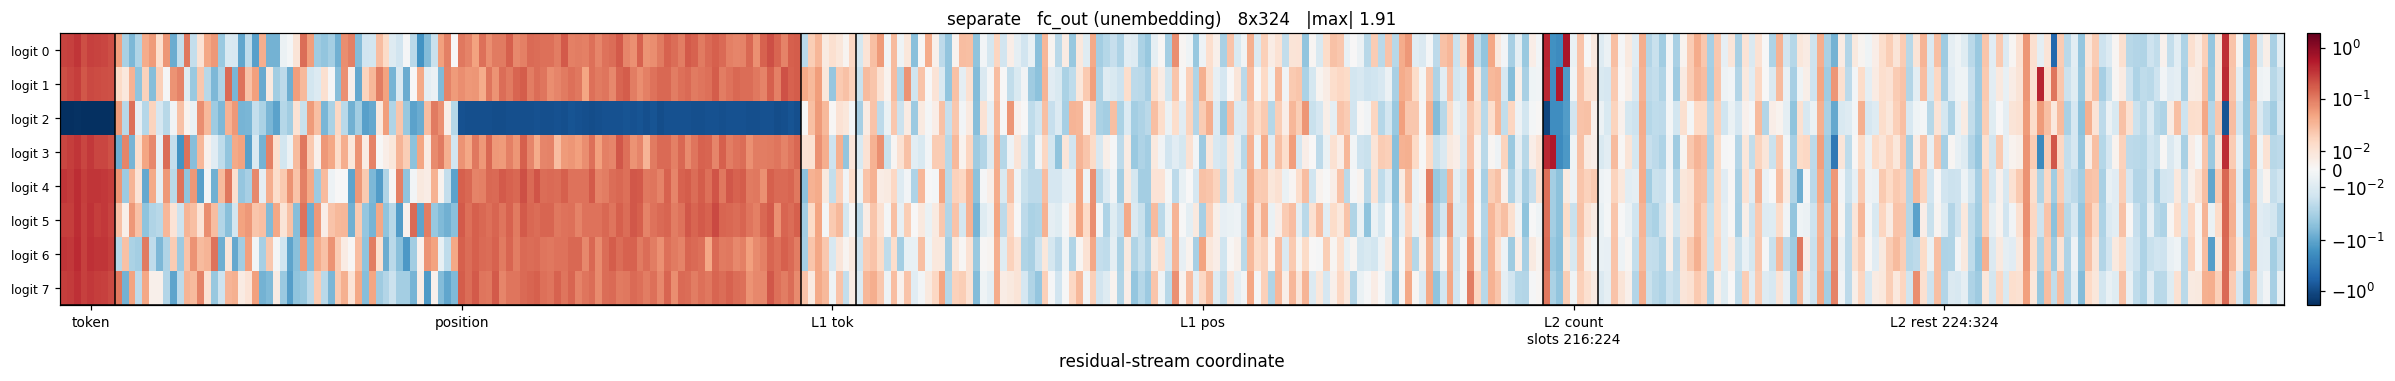

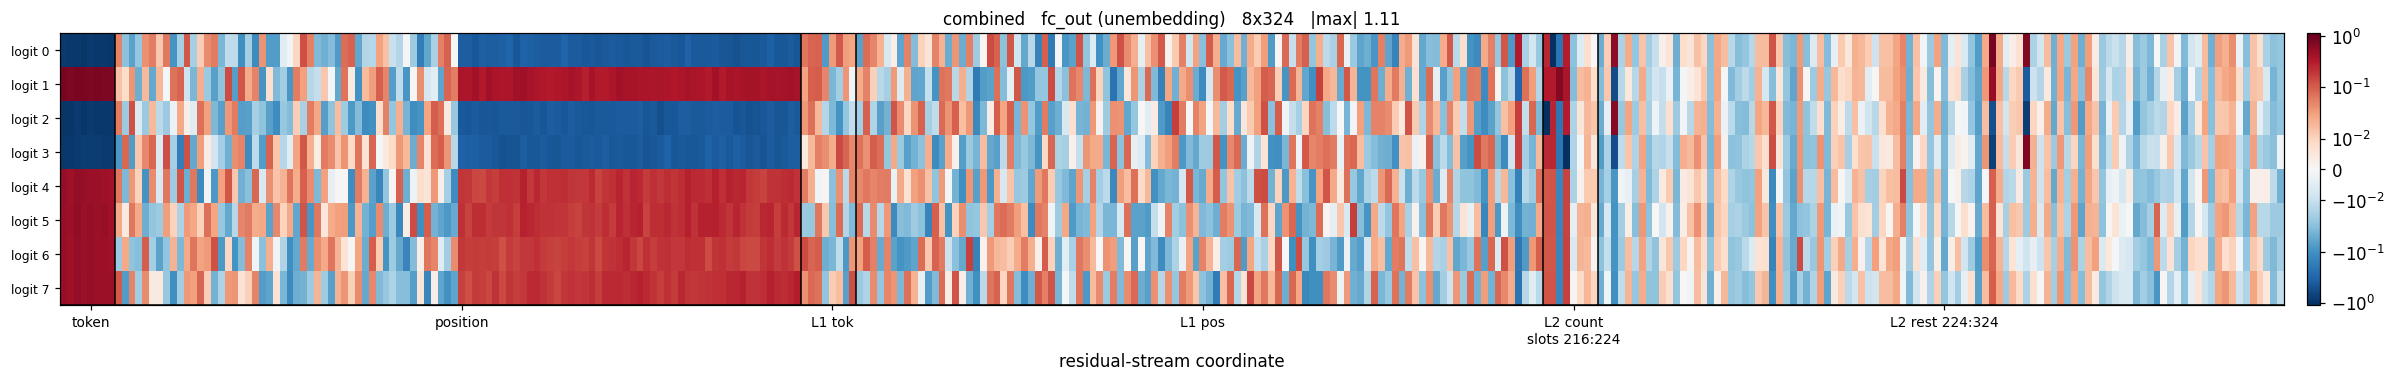

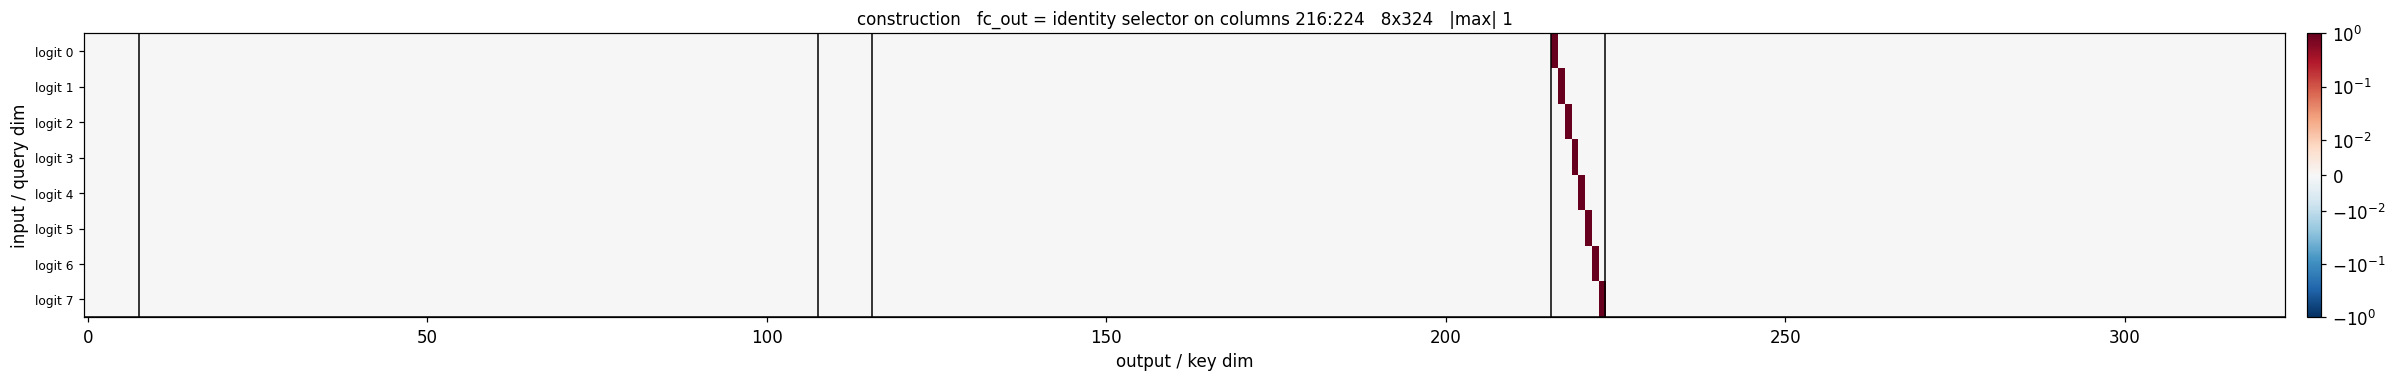

In [11]:
for a in ARCHS:
    fig, ax = plt.subplots(figsize=(22, 3.6))
    im = show(ax, FCL[a], f'{a}   fc_out (unembedding)', lw=1.0, aspect='auto')
    fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01)
    ax.set_yticks(range(V)); ax.set_yticklabels([f'logit {i}' for i in range(V)], fontsize=8)
    ax.set_xticks([V // 2, V + T // 2, D + V // 2, D + V + T // 2, IN2 + V // 2,
                   IN2 + V + T // 2])
    ax.set_xticklabels(['token', 'position', 'L1 tok', 'L1 pos', 'L2 count\nslots 216:224',
                        'L2 rest 224:324'], fontsize=9)
    ax.set_xlabel('residual-stream coordinate'); ax.set_ylabel('')
    fig.tight_layout()
    fig.savefig(os.path.join(ART, f'fcout_{a}_a{THR}.png'), bbox_inches='tight')
    plt.show()

fig, ax = plt.subplots(figsize=(22, 3.6))
im = show(ax, FC_C, 'construction   fc_out = identity selector on columns 216:224',
          lw=1.0, aspect='auto')
fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01)
ax.set_yticks(range(V)); ax.set_yticklabels([f'logit {i}' for i in range(V)], fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(ART, 'fcout_construction.png'), bbox_inches='tight')
plt.show()


fc_out column-block energy share  (construction: 100% in the count slots)

arch                           token 0:8            position 8:108        L1-out tok 108:116        L1-out pos 116:216    L2 count slots 216:224           L2 rest 224:324
construction                       0.0%                      0.0%                      0.0%                      0.0%                    100.0%                      0.0% 
separate                          38.3%                     54.6%                      0.1%                      0.5%                      3.8%                      2.7% 
combined                          35.4%                     48.6%                      0.3%                      3.4%                      6.0%                      6.4% 

fc_out bias  (construction: all zero -- the bias sits inside the log instead)

arch              logit 0    logit 1    logit 2    logit 3    logit 4    logit 5    logit 6    logit 7
separate           0.5348     0.5144    -3.2837     0.4275

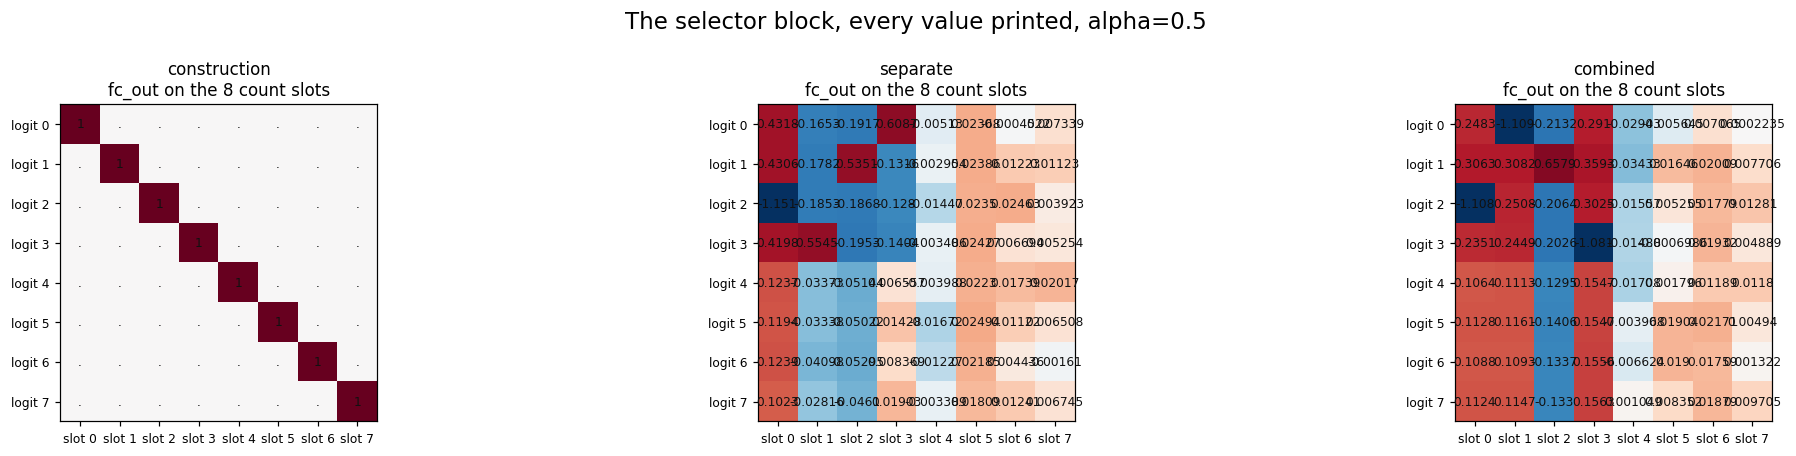

In [12]:
cblocks = [('token 0:8', 0, V), ('position 8:108', V, D),
           ('L1-out tok 108:116', D, D + V), ('L1-out pos 116:216', D + V, IN2),
           ('L2 count slots 216:224', IN2, IN2 + V),
           ('L2 signal slots 216:220', IN2, IN2 + VS),
           ('L2 rest 224:324', IN2 + V, DFULL)]

print('fc_out column-block energy share  (construction: 100% in the count slots)\n')
names = [b[0] for b in cblocks[:5]] + [cblocks[6][0]]
print(f'{"arch":14s}' + ''.join(f'{n:>26s}' for n in names))
for nm, M in [('construction', FC_C)] + [(a, FCL[a]) for a in ARCHS]:
    e = {n: float(M[:, c0:c1].norm()) ** 2 for n, c0, c1 in cblocks}
    tot = sum(e[n] for n, _, _ in cblocks[:5]) + e[cblocks[6][0]] or 1.0
    print(f'{nm:14s}' + ''.join(f'{e[n]/tot:>25.1%} ' for n in names))

print('\nfc_out bias  (construction: all zero -- the bias sits inside the log instead)\n')
print(f'{"arch":14s}' + ''.join(f'{"logit " + str(i):>11s}' for i in range(V)))
for a in ARCHS:
    print(f'{a:14s}' + ''.join(f'{float(x):11.4f}' for x in FCBL[a]))

fig, axes = plt.subplots(1, 3, figsize=(20, 4.2))
for ax, (nm, M, b) in zip(axes, [('construction', FC_C, FCB_C)] +
                                [(a, FCL[a], FCBL[a]) for a in ARCHS]):
    annot(ax, M, 0, V, IN2, IN2 + V, f'{nm}\nfc_out on the 8 count slots',
          rlab=[f'logit {i}' for i in range(V)], clab=[f'slot {i}' for i in range(V)], fs=8)
fig.suptitle(f'The selector block, every value printed, alpha={THR}', fontsize=15)
fig.tight_layout()
fig.savefig(os.path.join(ART, f'fcout_selector_a{THR}.png'), bbox_inches='tight')
plt.show()


## 9. The gauge-invariant object: $W_{ov}^{L2}\!\cdot\!\texttt{fc\_out}$

Section 6 and section 8 are each meaningless on their own, because
$W_{ov}\to W_{ov}M$, $\texttt{fc\_out}\to\texttt{fc\_out}M^{-1}$ is a symmetry of the relaxed
model. Their **composition** is not — it is exactly the map

$$E[u,v]\;=\;\sum_{j} \texttt{fc\_out}[u,\;216+j]\;\cdot\;W^{L2}_{ov}[v,\;j],$$

read as: *if layer 2 attends to a position whose own token is $v$, how much does that push logit
$u$?* The construction gives $E=I_8$ exactly. This is the panel to judge the value circuit by.

(The frozen log sits between the two, acting coordinate-wise on the four signal slots, so $E$ is
the pre-log linear map — it is what the count slots are built from.)


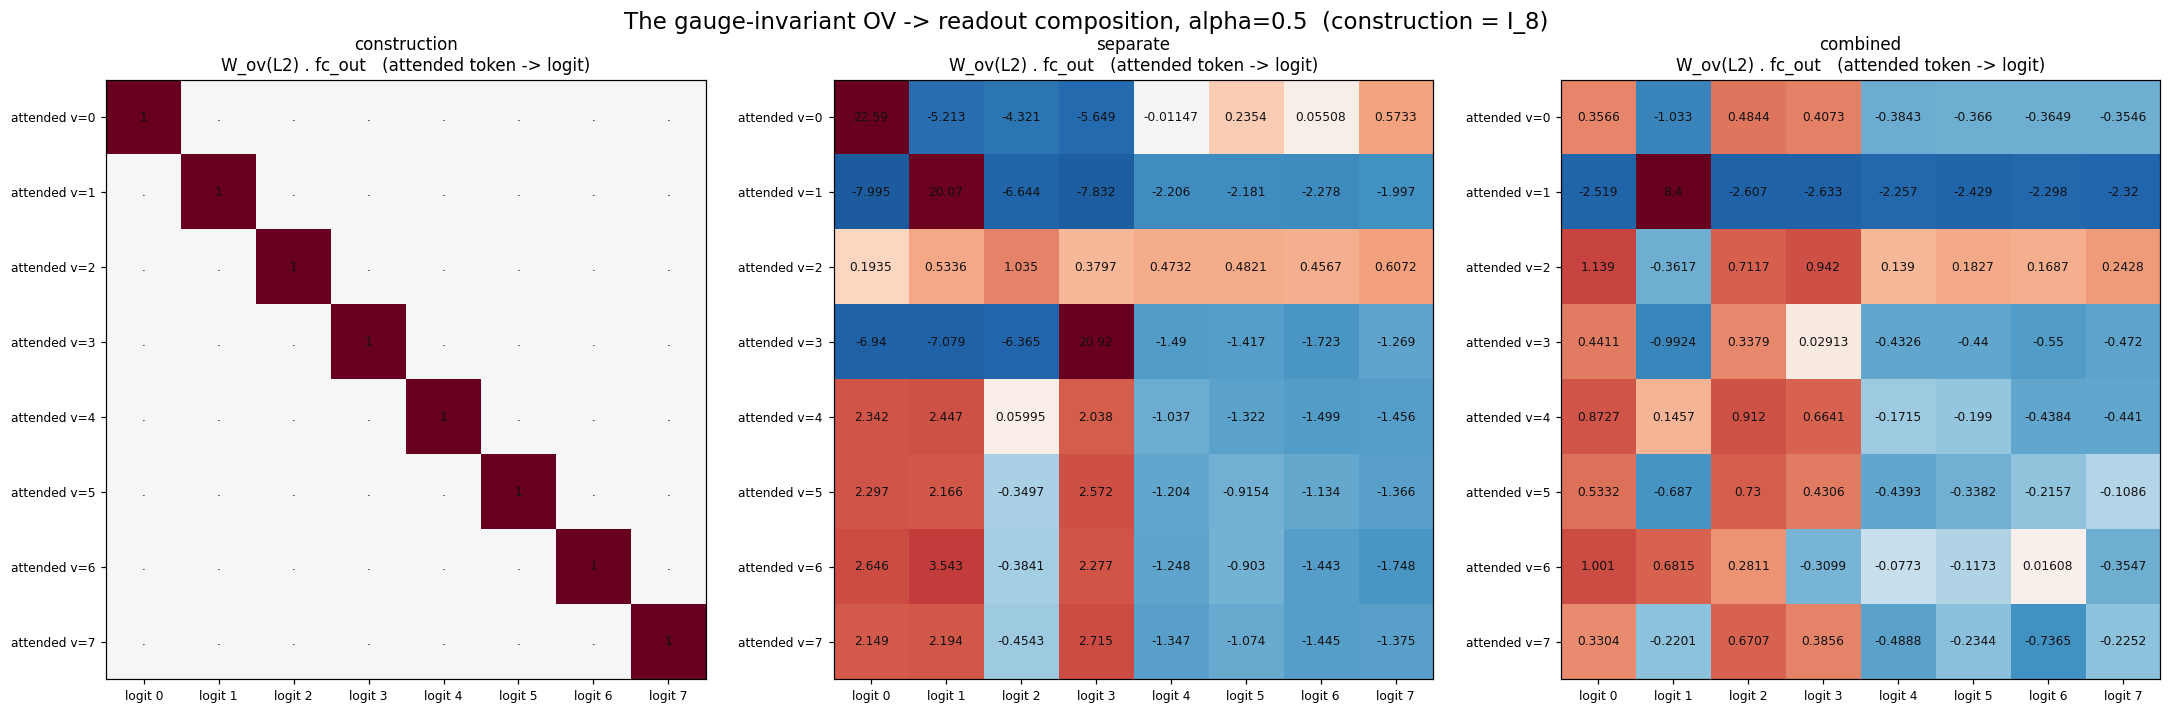

how identity-like is E?   diag/off = mean|diagonal| / mean|off-diagonal|

arch             diag/off (all 8)   diag/off (signal 4)   cos vs I_8  argmax == row
construction   999999999999999879147136483328.00 999999999999999879147136483328.00        1.000           8/8
separate                     3.95                  3.28        0.489           4/8
combined                     1.79                  2.05        0.275           1/8


In [13]:
def compose(arch):
    return OVL[arch][1][:V, :] @ FCL[arch][:, IN2:IN2 + D].t()   # [8 in-token, 8 logit]

E = {'construction': PROD['W_ov layer2'][:V, :] @ FC_C[:, IN2:IN2 + D].t()}
for a in ARCHS:
    E[a] = compose(a)

fig, axes = plt.subplots(1, 3, figsize=(20, 6.4))
for ax, nm in zip(axes, ['construction'] + ARCHS):
    annot(ax, E[nm], 0, V, 0, V, f'{nm}\nW_ov(L2) . fc_out   (attended token -> logit)',
          rlab=[f'attended v={i}' for i in range(V)],
          clab=[f'logit {i}' for i in range(V)], fs=8)
fig.suptitle(f'The gauge-invariant OV -> readout composition, alpha={THR}  '
             '(construction = I_8)', fontsize=15)
fig.tight_layout()
fig.savefig(os.path.join(ART, f'ov_readout_composition_a{THR}.png'), bbox_inches='tight')
plt.show()

print('how identity-like is E?   diag/off = mean|diagonal| / mean|off-diagonal|\n')
print(f'{"arch":14s} {"diag/off (all 8)":>18s} {"diag/off (signal 4)":>21s} '
      f'{"cos vs I_8":>12s} {"argmax == row":>14s}')
for nm in ['construction'] + ARCHS:
    A = E[nm].numpy()
    dg = np.abs(np.diag(A)).mean()
    of = np.abs(A - np.diag(np.diag(A))).sum() / (A.size - V)
    a4 = A[:VS, :VS]
    dg4 = np.abs(np.diag(a4)).mean()
    of4 = np.abs(a4 - np.diag(np.diag(a4))).sum() / (a4.size - VS)
    hit = int((A.argmax(axis=1) == np.arange(V)).sum())
    print(f'{nm:14s} {dg/max(of,1e-30):18.2f} {dg4/max(of4,1e-30):21.2f} '
          f'{cos(E[nm], torch.eye(V)):12.3f} {hit:>11d}/8')


## 10. Across all seven thresholds

The induction block ($W_{qk}$ L2, own token $\times$ key predecessor) and the OV$\to$readout
composition, for every $\alpha$ and both architectures. The construction's values are
$\text{diag/off}=\infty$ for both.


thresholds found: [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]


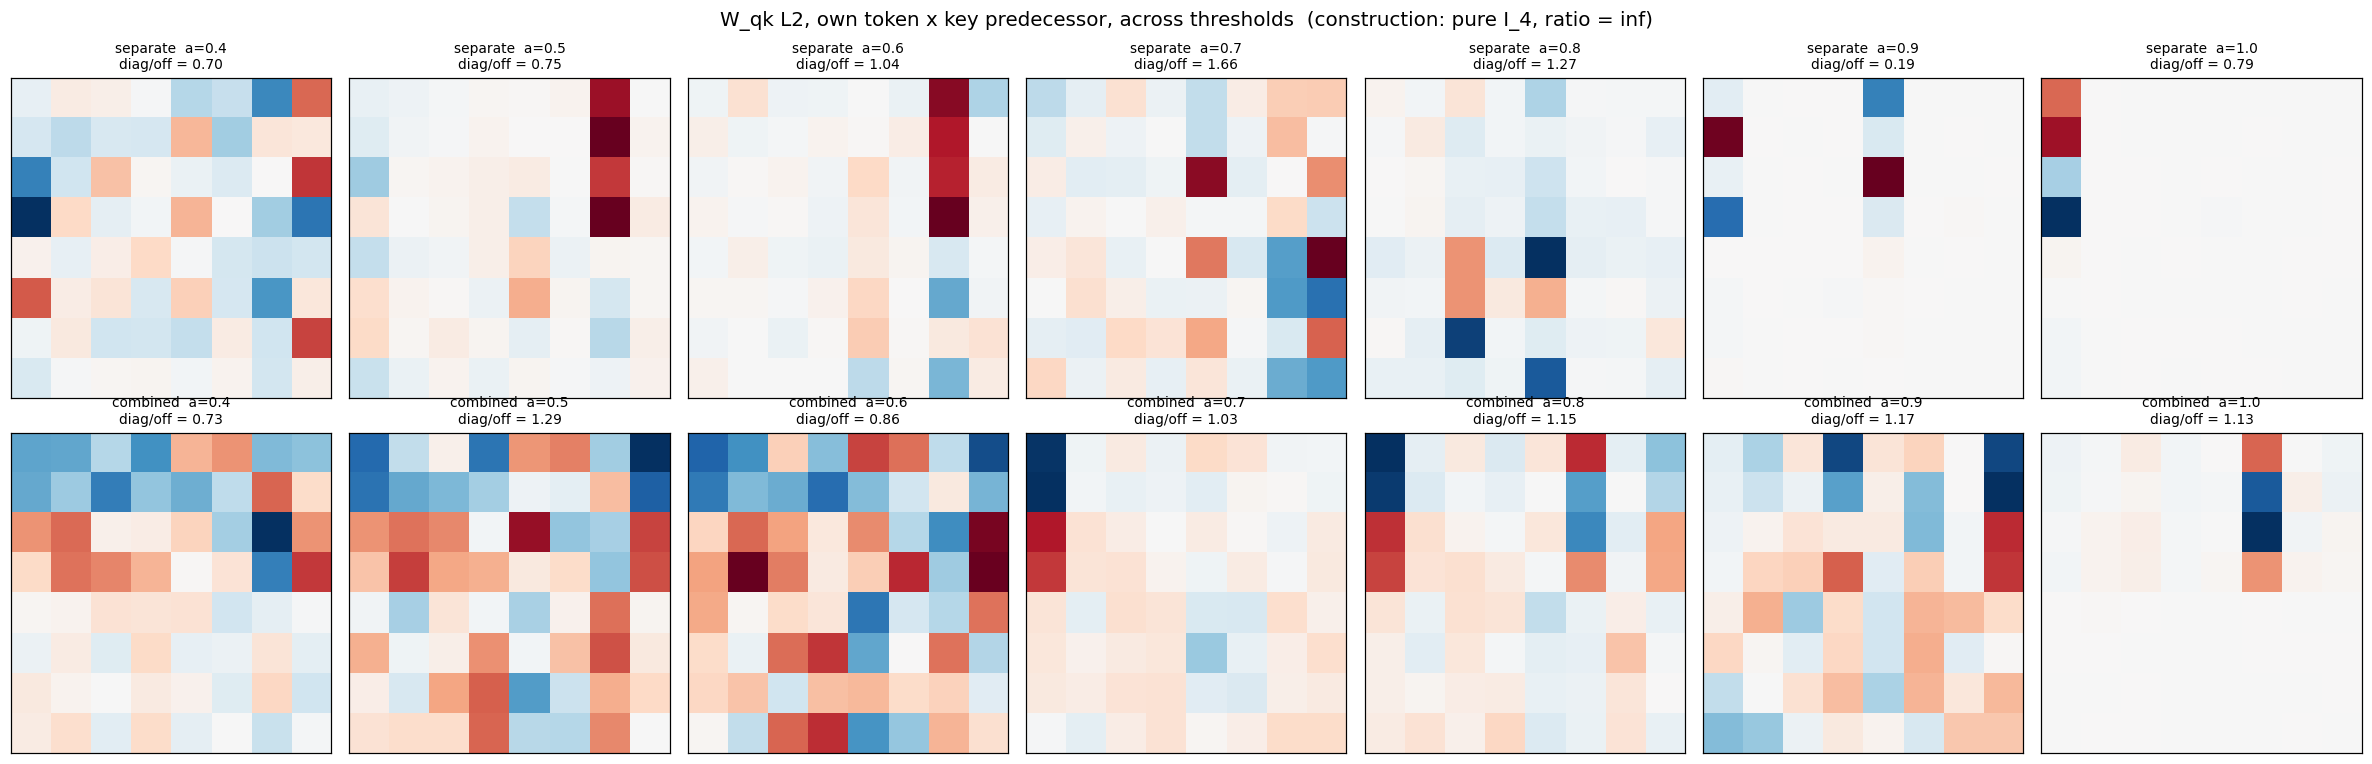

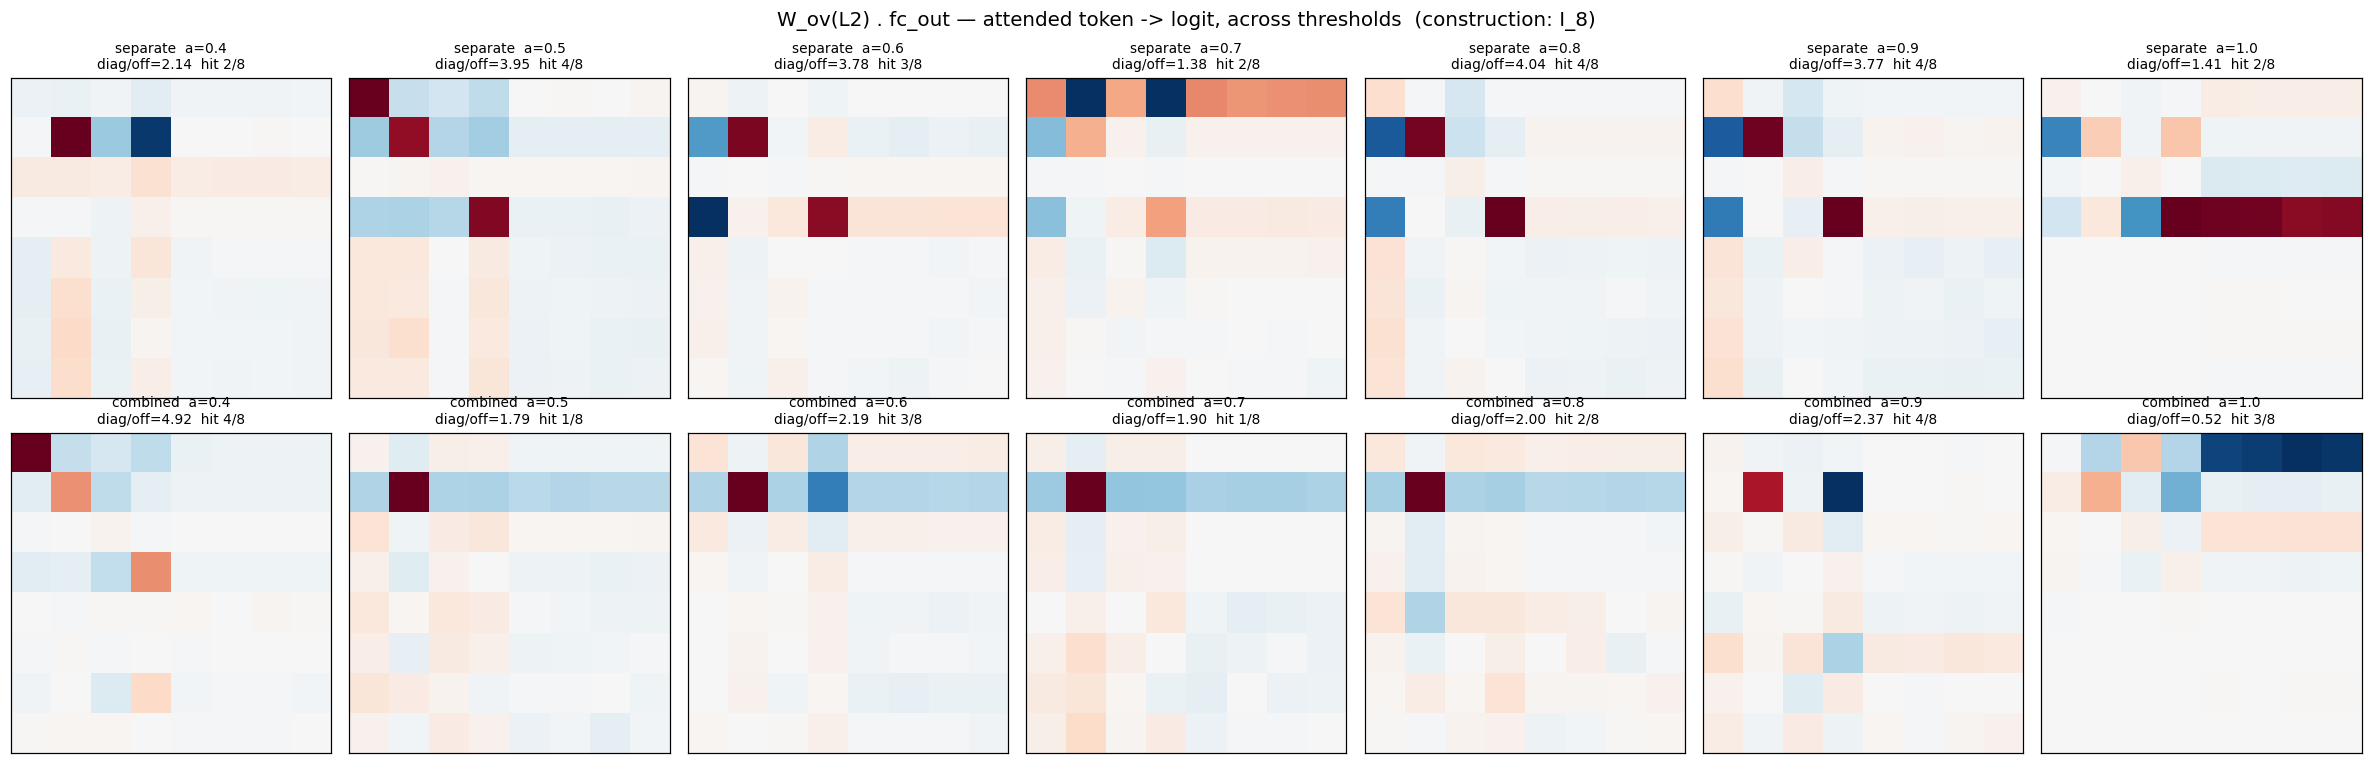

In [14]:
ALL_THRS = sorted(float(p.split('_x_')[1][:-4])
                  for p in glob.glob(os.path.join(CDIR, 'model_separate_*.pth')))
print('thresholds found:', ALL_THRS)

CACHE = {}
def get(a, t):
    if (a, t) not in CACHE:
        m = load(a, t)
        q, o, _ = eff(m)
        CACHE[(a, t)] = (q, o, m.fc_out.weight.detach(), m.fc_out.bias.detach())
    return CACHE[(a, t)]

fig, axes = plt.subplots(2, len(ALL_THRS), figsize=(3.1 * len(ALL_THRS), 7.2))
for j, t in enumerate(ALL_THRS):
    for i, a in enumerate(ARCHS):
        b = get(a, t)[0][1][:V, D:D + V].numpy()
        v = np.abs(b).max() or 1.0
        axes[i][j].imshow(b, cmap='RdBu_r', vmin=-v, vmax=v, interpolation='nearest')
        s = b[:VS, :VS]
        dg = np.abs(np.diag(s)).mean()
        of = np.abs(s - np.diag(np.diag(s))).sum() / (s.size - VS)
        axes[i][j].set_title(f'{a}  a={t}\ndiag/off = {dg/max(of,1e-30):.2f}', fontsize=9)
        axes[i][j].set_xticks([]); axes[i][j].set_yticks([])
fig.suptitle('W_qk L2, own token x key predecessor, across thresholds  '
             '(construction: pure I_4, ratio = inf)', fontsize=13)
fig.tight_layout()
fig.savefig(os.path.join(ART, 'wqk2_block_all_thresholds.png'), bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(2, len(ALL_THRS), figsize=(3.1 * len(ALL_THRS), 7.2))
for j, t in enumerate(ALL_THRS):
    for i, a in enumerate(ARCHS):
        q, o, fc, _ = get(a, t)
        b = (o[1][:V, :] @ fc[:, IN2:IN2 + D].t()).numpy()
        v = np.abs(b).max() or 1.0
        axes[i][j].imshow(b, cmap='RdBu_r', vmin=-v, vmax=v, interpolation='nearest')
        dg = np.abs(np.diag(b)).mean()
        of = np.abs(b - np.diag(np.diag(b))).sum() / (b.size - V)
        hit = int((b.argmax(axis=1) == np.arange(V)).sum())
        axes[i][j].set_title(f'{a}  a={t}\ndiag/off={dg/max(of,1e-30):.2f}  hit {hit}/8',
                             fontsize=9)
        axes[i][j].set_xticks([]); axes[i][j].set_yticks([])
fig.suptitle('W_ov(L2) . fc_out — attended token -> logit, across thresholds  '
             '(construction: I_8)', fontsize=13)
fig.tight_layout()
fig.savefig(os.path.join(ART, 'ov_readout_all_thresholds.png'), bbox_inches='tight')
plt.show()


In [15]:
print('summary across thresholds\n')
print(f'{"alpha":>6s} {"arch":10s} {"best_test":>10s} {"|Wqk1|/c":>10s} {"|Wqk2|/c":>10s} '
      f'{"cos Wqk2":>9s} {"induc d/o":>10s} {"E d/o":>8s} {"E hit":>6s} {"fc slots%":>10s}')
for t in ALL_THRS:
    for a in ARCHS:
        q, o, fc, _ = get(a, t)
        met = json.load(open(os.path.join(CDIR, f'metrics_{a}_seed0_x_{t}.json')))
        s = q[1][:V, D:D + V].numpy()[:VS, :VS]
        dg = np.abs(np.diag(s)).mean()
        of = np.abs(s - np.diag(np.diag(s))).sum() / (s.size - VS)
        Em = (o[1][:V, :] @ fc[:, IN2:IN2 + D].t()).numpy()
        edg = np.abs(np.diag(Em)).mean()
        eof = np.abs(Em - np.diag(np.diag(Em))).sum() / (Em.size - V)
        hit = int((Em.argmax(axis=1) == np.arange(V)).sum())
        share = float(fc[:, IN2:IN2 + V].norm()) ** 2 / float(fc.norm()) ** 2
        print(f'{t:6.1f} {a:10s} {met["best_test"]:10.4f} '
              f'{float(q[0].norm()/PROD["W_qk layer1"].norm()):10.3g} '
              f'{float(q[1].norm()/PROD["W_qk layer2"].norm()):10.3g} '
              f'{cos(q[1], PROD["W_qk layer2"]):9.3f} {dg/max(of,1e-30):10.2f} '
              f'{edg/max(eof,1e-30):8.2f} {hit:>4d}/8 {share:10.1%}')
    print()


summary across thresholds

 alpha arch        best_test   |Wqk1|/c   |Wqk2|/c  cos Wqk2  induc d/o    E d/o  E hit  fc slots%
   0.4 separate       1.8123   6.59e-08   2.27e-05     0.397       0.70     2.14    2/8      16.7%
   0.4 combined       1.8698   7.52e-09   2.01e-05     0.083       0.73     4.92    4/8       7.5%

   0.5 separate       1.7616   6.16e-08   2.88e-05     0.114       0.75     3.95    4/8       3.8%
   0.5 combined       1.8079   6.55e-09   1.64e-05     0.122       1.29     1.79    1/8       6.0%

   0.6 separate       1.6636   3.95e-08   2.86e-05     0.240       1.04     3.78    3/8      11.2%
   0.6 combined       1.7041   8.22e-09    1.6e-05     0.126       0.86     2.19    3/8       6.9%

   0.7 separate       1.5290   3.78e-08   3.03e-05     0.242       1.66     1.38    2/8      10.3%
   0.7 combined       1.5540   6.97e-09   1.65e-05     0.123       1.03     1.90    1/8       8.3%

   0.8 separate       1.3524   2.62e-08   2.57e-05     0.216       1.27     4.

## 11. What to take from this

Read against section 6 of `obesrving_the_weights.ipynb` (the construction's target pattern) and
against the qk-only panels in its section 7:

* **Amplitude.** As in the pinned run, $\|W_{qk}\|_F$ stays a tiny fraction of the construction's.
  GD never travels the eight orders of magnitude to the $-10^9$ suppressions, because only the
  softmax's *ordering* matters.
* **Density.** The construction is 0.10% non-zero in layer 2; every learned matrix here is fully
  dense — the right structure plus a lot of small noise the softmax ignores.
* **The two new circuits.** $W_{ov}$ and `fc_out` are individually unreadable (pure gauge), but
  their composition in section 9 is not. If $E$ comes out close to a scaled identity — high
  diag/off, `hit 8/8` — GD has rediscovered the construction's value circuit up to that gauge,
  which is the strongest statement the relaxed setting allows.
* **Where the unembedding looks.** The column-block table in section 8 says how much of `fc_out`'s
  energy sits on the eight count slots versus the 316 coordinates the construction ignores. A high
  share means GD converged on the same readout the construction hard-codes; a low share means it
  found some other route to the logits and the "count slot" interpretation is weaker here.
* **The bias.** The construction has none — its pseudo-counts live inside the log. Whatever
  `fc_out.bias` learned is the relaxed run's own version of the noise floor, and it should track
  $\log\frac{1-\alpha}{4}$ in shape across $\alpha$.
* **`separate` vs `combined`.** Section 10's table puts `best_test` next to every structural
  number, so the CE gap can be read against which circuit degraded.
